# Air Quality UCI — Data Analysis & Visualisation Project
**UE Data analysis & visualisation** · Team: Pablo Reche, Ignacio Argüelles and José María Duro Agea

Full workflow: **data loading → data wrangling → EDA & interactive visual analytics → predictive modelling (regression) → explainable AI (SHAP) → conclusions**.


## 0. Context
- **Dataset:** 9,357 hourly records (March 2004 – April 2005) from an *Air Quality Chemical Multisensor Device* placed at road level in a polluted area of an Italian city.
- **Inputs:** 5 low-cost metal-oxide sensors (`PT08.S1`…`PT08.S5`) + temperature (T), relative humidity (RH), absolute humidity (AH).
- **Ground truth (GT):** hourly concentrations of CO, NMHC, Benzene (C6H6), NOx and NO2 measured by a certified reference analyzer.
- **Known issues:** missing values coded as `-200`, sensor cross-sensitivity, concept and sensor drift (De Vito et al., 2008).

**Research questions**
1. What are the temporal patterns of pollution (hour of day, weekday vs weekend, season)?
2. How strongly do the cheap sensors relate to the certified measurements?
3. **Can we predict the real CO concentration (`CO(GT)`) from the cheap sensors and weather**, so that the low-cost device could replace the certified analyzer?
4. Which features drive the predictions (SHAP), and does the model degrade over time (sensor drift)?

## 1. Setup

In [1]:
# Colab already has pandas, sklearn, seaborn, plotly, xgboost. SHAP may need installing.
!pip -q install shap xgboost plotly

import os, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
MISSING_CODE = -200   # value the dataset uses to tag a missing measurement

c:\Users\jmdur\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data loading
The notebook looks for `AirQualityUCI.csv` in the working directory. If it is not there, it downloads it from the UCI repository; if that fails, it asks you to upload the file (the CSV from `Dataset_airquality.zip`).

In [2]:
CSV = "AirQualityUCI.csv"
if not os.path.exists(CSV):
    try:
        url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"
        urllib.request.urlretrieve(url, "air_quality.zip")
        zipfile.ZipFile("air_quality.zip").extractall(".")
        print("Downloaded from UCI")
    except Exception as e:
        print("Download failed -> upload AirQualityUCI.csv manually", e)
        from google.colab import files
        files.upload()

# Format: ';' separator and ',' as decimal mark (European CSV)
raw = pd.read_csv(CSV, sep=";", decimal=",")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(15), object(2)
memory usage: 1.2+ MB


In [4]:
# The minimum of every numeric column is -200: the missing-value code
raw.describe().T[["count", "mean", "min", "max"]]

,count,mean,min,max
CO(GT),9357.0,-34.207524,-200.0,11.900
PT08.S1(CO),9357.0,1048.990061,-200.0,2040.000
NMHC(GT),9357.0,-159.090093,-200.0,1189.000
C6H6(GT),9357.0,1.865683,-200.0,63.700
PT08.S2(NMHC),9357.0,894.595276,-200.0,2214.000
NOx(GT),9357.0,168.616971,-200.0,1479.000
PT08.S3(NOx),9357.0,794.990168,-200.0,2683.000
NO2(GT),9357.0,58.148873,-200.0,340.000
PT08.S4(NO2),9357.0,1391.479641,-200.0,2775.000
PT08.S5(O3),9357.0,975.072032,-200.0,2523.000


## 3. Data Wrangling

### 3.1 Remove empty columns and empty rows

In [5]:
df = raw.copy()
empty_cols = [c for c in df.columns if df[c].isna().all()]
df = df.drop(columns=empty_cols)
n_before = len(df)
df = df.dropna(how="all")
print("Dropped empty columns:", empty_cols)
print(f"Dropped {n_before - len(df)} completely empty rows")
print(f"New dataset is {df.shape}")

Dropped empty columns: ['Unnamed: 15', 'Unnamed: 16']
Dropped 114 completely empty rows
New dataset is (9357, 15)


### 3.2 Type conversion: build a datetime index

In [6]:
df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H.%M.%S")
df = df.drop(columns=["Date", "Time"]).set_index("Datetime").sort_index()

full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Period:", df.index.min(), "->", df.index.max())
print("Duplicated timestamps:", df.index.duplicated().sum())
print("Missing hours in the time grid:", len(full_range.difference(df.index)))

Period: 2004-03-10 18:00:00 -> 2005-04-04 14:00:00
Duplicated timestamps: 0
Missing hours in the time grid: 0


### 3.3 Rename columns (shorter, readable names)

In [7]:
df = df.rename(columns={
    "CO(GT)": "CO_GT", "PT08.S1(CO)": "S1_CO", "NMHC(GT)": "NMHC_GT",
    "C6H6(GT)": "C6H6_GT", "PT08.S2(NMHC)": "S2_NMHC", "NOx(GT)": "NOx_GT",
    "PT08.S3(NOx)": "S3_NOx", "NO2(GT)": "NO2_GT", "PT08.S4(NO2)": "S4_NO2",
    "PT08.S5(O3)": "S5_O3",
})
GT_COLS = ["CO_GT", "NMHC_GT", "C6H6_GT", "NOx_GT", "NO2_GT"]
SENSOR_COLS = ["S1_CO", "S2_NMHC", "S3_NOx", "S4_NO2", "S5_O3"]
WEATHER_COLS = ["T", "RH", "AH"]

# Units from the UCI variable table. NOx is in ppb while NO2 and benzene are in µg/m³,
# so pollutants with different units must never share an axis.
UNITS = {"CO_GT": "mg/m³", "NMHC_GT": "µg/m³", "C6H6_GT": "µg/m³", "NOx_GT": "ppb",
         "NO2_GT": "µg/m³", "T": "°C", "RH": "%"}
df.columns.tolist()

['CO_GT',
 'S1_CO',
 'NMHC_GT',
 'C6H6_GT',
 'S2_NMHC',
 'NOx_GT',
 'S3_NOx',
 'NO2_GT',
 'S4_NO2',
 'S5_O3',
 'T',
 'RH',
 'AH']

### 3.4 Missing values: `-200` → `NaN`

In [8]:
df = df.replace(MISSING_CODE, np.nan)
missing = pd.DataFrame({"n_missing": df.isna().sum(), "pct_missing": (df.isna().mean() * 100).round(1)})
missing.sort_values("pct_missing", ascending=False)

,n_missing,pct_missing
NMHC_GT,8443,90.2
CO_GT,1683,18.0
NOx_GT,1639,17.5
NO2_GT,1642,17.5
S1_CO,366,3.9
S2_NMHC,366,3.9
C6H6_GT,366,3.9
S3_NOx,366,3.9
S4_NO2,366,3.9
S5_O3,366,3.9


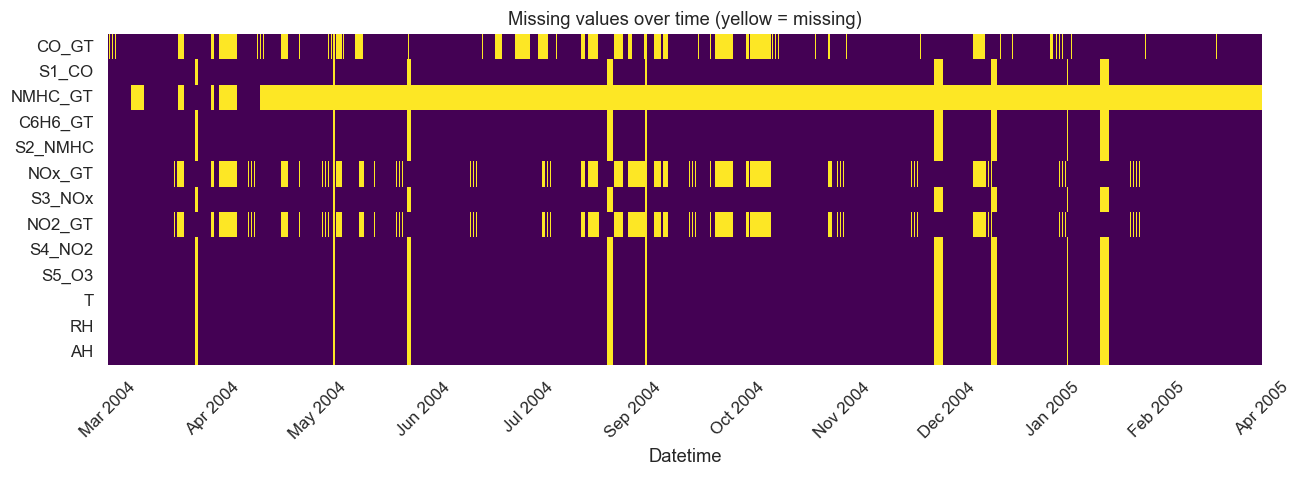

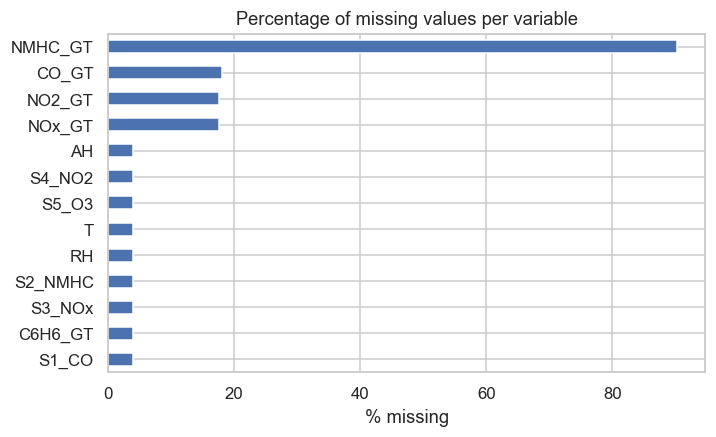

In [9]:
# Missing-value heatmap over time (yellow = missing)
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(df.isna().T, cbar=False, cmap="viridis", ax=ax)
ticks = np.linspace(0, len(df) - 1, 12).astype(int)
ax.set_xticks(ticks)
ax.set_xticklabels(df.index[ticks].strftime("%b %Y"), rotation=45)
ax.set_title("Missing values over time (yellow = missing)")
plt.tight_layout(); plt.show()

missing["pct_missing"].sort_values().plot.barh(figsize=(7, 4), color="#4C72B0")
plt.xlabel("% missing"); plt.title("Percentage of missing values per variable"); plt.show()

In [10]:
# Structure of the missingness
sensor_down = df["S1_CO"].isna()
print("Rows where ALL sensors + weather are missing:", int(df.loc[sensor_down, SENSOR_COLS + WEATHER_COLS + ["C6H6_GT"]].isna().all(axis=1).sum()))
print("Last valid NMHC_GT measurement:", df["NMHC_GT"].last_valid_index())

Rows where ALL sensors + weather are missing: 366
Last valid NMHC_GT measurement: 2004-05-01 00:00:00


**Decisions**
- **Drop `NMHC_GT`**: ~90% missing, the reference analyzer stopped measuring it after a few months, so it is impossible to impute reliably.
- **Rows where the multisensor device was down (all sensors + weather missing, 366 h)** removed: they carry no input information.
- **`CO_GT`, `NOx_GT`, `NO2_GT` (~18% missing)**: for **EDA** we fill **only short gaps (at most 3 consecutive missing hours)** with time interpolation, and never across a device failure. Longer gaps stay missing. For **modelling** we only train/evaluate on rows with a *real* target value: we never train a model on an imputed target.
- **Why only short gaps (measured in the next cell):** hourly CO is strongly correlated with the previous hour (r = 0.84), but the correlation fades quickly (0.60 at 2 h, 0.43 at 3 h, 0.16 at 6 h). With gaps of at most 3 missing hours, every filled value is at most 2 hours from a real measurement (r ≥ 0.60), so a straight line between neighbours is a reasonable estimate. Over longer gaps it would be guesswork, and could cut straight through a rush-hour peak.

In [11]:
# How quickly does CO "forget" its past? Autocorrelation of hourly CO at increasing time lags.
# df is still the complete hourly grid here (device-down rows are removed in the next cell),
# so a lag of k rows is exactly k hours.
MAX_LAG_HOURS = 6
autocorr = pd.Series({lag: df["CO_GT"].autocorr(lag) for lag in range(1, MAX_LAG_HOURS + 1)}, name="r")
autocorr.index.name = "lag (hours)"
autocorr.round(2).to_frame()

,r
lag (hours),
1,0.84
2,0.60
3,0.43
4,0.32
5,0.23
6,0.16


In [12]:
n0 = len(df)
df = df.drop(columns=["NMHC_GT"])
df = df[~df["S1_CO"].isna()].copy()
print(f"Removed {n0 - len(df)} device-down rows -> {df.shape}")

INTERP_COLS = ["CO_GT", "NOx_GT", "NO2_GT"]
MAX_GAP_HOURS = 3   # longest run of consecutive missing hours we are willing to fill

# Keep a flag of which target values are real measurements (used for modelling)
for c in INTERP_COLS:
    df[f"{c}_is_real"] = df[c].notna()

def interpolate_short_gaps(s, max_gap_hours=MAX_GAP_HOURS):
    """Time-interpolate only gaps of at most `max_gap_hours` consecutive missing hours.

    pandas' interpolate(limit=n) is not enough: it also fills the first n values of LONG gaps, and since
    the device-down rows were removed it can interpolate across days. Here a missing value is filled only
    if the real measurements on both sides are at most max_gap_hours + 1 hours apart (real time, not rows).
    """
    real_times = pd.Series(s.index.where(s.notna()), index=s.index)
    span_hours = (real_times.bfill() - real_times.ffill()).dt.total_seconds() / 3600
    interpolated = s.interpolate(method="time", limit_area="inside")
    return interpolated.where(s.notna() | (span_hours <= max_gap_hours + 1))

# EDA version: time interpolation of short gaps only
df_eda = df.copy()
for c in INTERP_COLS:
    df_eda[c] = interpolate_short_gaps(df[c])

# Compared with pandas' built-in limit, which would also fill the start of long gaps and bridge device failures
pandas_limit = {c: df[c].interpolate(method="time", limit=MAX_GAP_HOURS) for c in INTERP_COLS}
pd.DataFrame({"filled_values": [(df[c].isna() & df_eda[c].notna()).sum() for c in INTERP_COLS],
              "filled_by_pandas_limit": [(df[c].isna() & pandas_limit[c].notna()).sum() for c in INTERP_COLS],
              "still_missing": [df_eda[c].isna().sum() for c in INTERP_COLS]}, index=INTERP_COLS)

Removed 366 device-down rows -> (8991, 12)


,filled_values,filled_by_pandas_limit,still_missing
CO_GT,162,257,1485
NOx_GT,312,376,1283
NO2_GT,313,377,1285


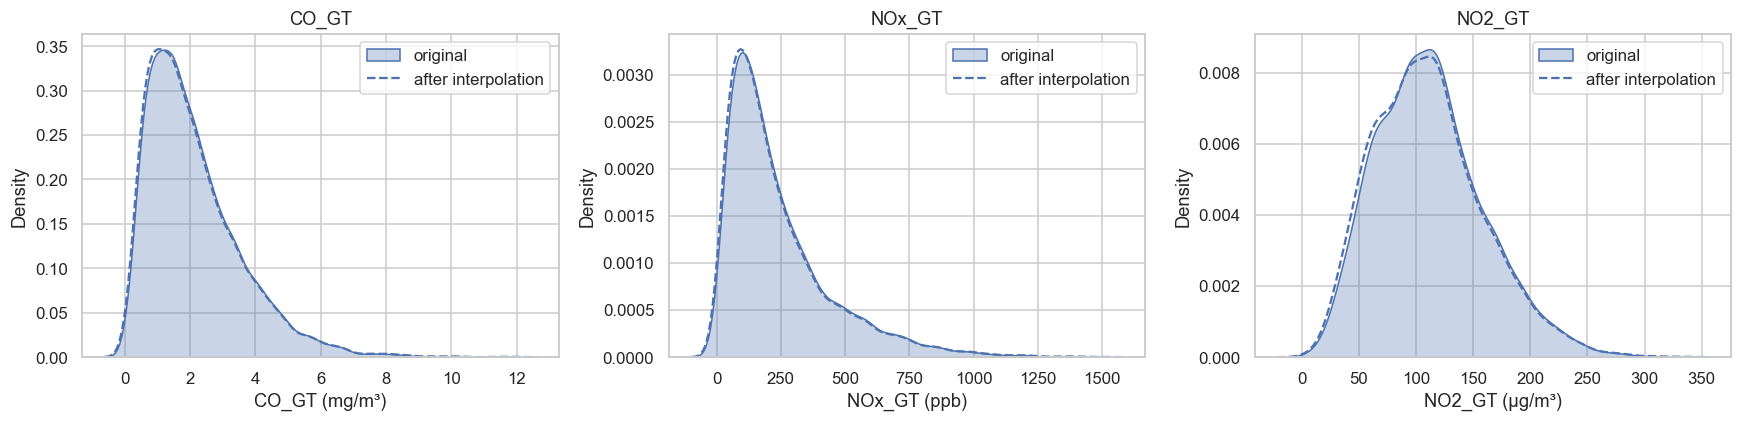

count     mean      std   q25    q50    q75
variable version                                                  
CO_GT    original       7344    2.130    1.436   1.1    1.8    2.8
         interpolated   7506    2.104    1.438   1.0    1.8    2.8
NOx_GT   original       7396  242.189  206.312  97.0  178.0  321.0
         interpolated   7708  236.869  204.952  93.0  173.0  315.0
NO2_GT   original       7393  112.145   47.629  77.0  109.0  140.0
         interpolated   7706  110.450   47.940  74.0  107.0  139.0

In [13]:
# Does the short-gap interpolation distort the distributions used in the EDA?
QUANTILES = [0.25, 0.5, 0.75]
rows = []
for c in INTERP_COLS:
    for version, s in [("original", df[c]), ("interpolated", df_eda[c])]:
        s = s.dropna()
        rows.append({"variable": c, "version": version, "count": len(s), "mean": s.mean(), "std": s.std(),
                     **{f"q{int(q * 100)}": s.quantile(q) for q in QUANTILES}})

fig, axes = plt.subplots(1, len(INTERP_COLS), figsize=(16, 4))
for ax, c in zip(axes, INTERP_COLS):
    sns.kdeplot(df[c].dropna(), ax=ax, fill=True, alpha=.3, label="original")
    sns.kdeplot(df_eda[c].dropna(), ax=ax, ls="--", label="after interpolation")
    ax.set(xlabel=f"{c} ({UNITS[c]})", ylabel="Density", title=c)
    ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index(["variable", "version"]).round(3)

CO missing: 18% of all hours, 54% at 4 h
Filled CO values: 162, of which at 4 h: 133 (82%)
Mean real CO at 4 h: 0.74 vs 2.13 mg/m³ overall


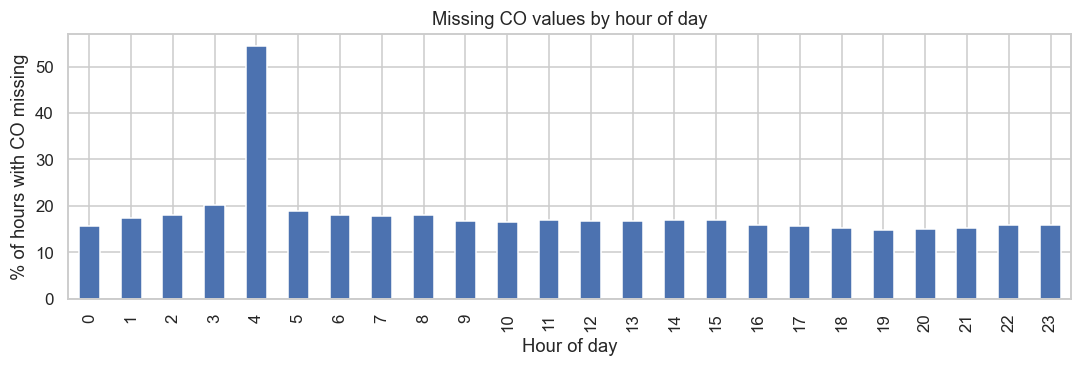

In [14]:
# Which hours did the interpolation fill? Missing reference values are not spread evenly over the day.
co_missing_pct_by_hour = df["CO_GT"].isna().groupby(df.index.hour).mean() * 100
filled_co = df["CO_GT"].isna() & df_eda["CO_GT"].notna()
filled_by_hour = filled_co.groupby(df.index.hour).sum()
worst_hour = co_missing_pct_by_hour.idxmax()

print(f"CO missing: {df['CO_GT'].isna().mean():.0%} of all hours, {co_missing_pct_by_hour[worst_hour]:.0f}% at {worst_hour} h")
print(f"Filled CO values: {filled_co.sum()}, of which at {worst_hour} h: {filled_by_hour[worst_hour]} "
      f"({filled_by_hour[worst_hour] / filled_co.sum():.0%})")
print(f"Mean real CO at {worst_hour} h: {df.loc[df.index.hour == worst_hour, 'CO_GT'].mean():.2f} "
      f"vs {df['CO_GT'].mean():.2f} {UNITS['CO_GT']} overall")

ax = co_missing_pct_by_hour.plot.bar(figsize=(10, 3.5), color="#4C72B0")
ax.set(xlabel="Hour of day", ylabel="% of hours with CO missing", title="Missing CO values by hour of day")
plt.tight_layout(); plt.show()

#### Check: does the interpolation distort the distributions?
- **No visible distortion:** the distributions before and after interpolation practically overlap. For CO the mean goes from 2.130 to 2.104 mg/m³, the median stays at 1.8 and the standard deviation goes from 1.436 to 1.438; NOx and NO2 move the same way by a similarly small amount (mean −2.2% and −1.5%).
- **Why the mean drops slightly:** the reference values are not missing at random. CO is missing 54% of the time at 4 h (18% overall), so 82% of the filled CO values (133 of 162) are at 4 h, a low-pollution hour (mean 0.74 mg/m³ vs 2.13 overall). The original data under-represent the clean night hours and slightly overstate the average level; the interpolation partly corrects this bias rather than creating one.
- **Consequence for the EDA:** the night-time points of the daily profile (Section 4.7), especially 4 h, rest on fewer days than the rest of the day.

### 3.5 Duplicates

In [15]:
print("Duplicated rows (all values identical):", df.duplicated().sum())

Duplicated rows (all values identical): 0


### 3.6 Outlier detection (IQR rule)

In [16]:
IQR_FACTOR = 1.5   # Tukey's rule
num_cols = ["CO_GT", "C6H6_GT", "NOx_GT", "NO2_GT"] + SENSOR_COLS + WEATHER_COLS

def iqr_bounds(s, factor=IQR_FACTOR):
    """Lower and upper fences of the IQR rule."""
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - factor * iqr, q3 + factor * iqr

def iqr_outlier_mask(s, factor=IQR_FACTOR):
    """True where a value lies outside the IQR fences."""
    low, high = iqr_bounds(s, factor)
    return (s < low) | (s > high)

fences = {c: iqr_bounds(df[c]) for c in num_cols}
outl = pd.DataFrame({"below": [(df[c] < fences[c][0]).sum() for c in num_cols],
                     "above": [(df[c] > fences[c][1]).sum() for c in num_cols]}, index=num_cols)
outl["n_outliers"] = outl["below"] + outl["above"]
outl["pct"] = (outl["n_outliers"] / df[num_cols].notna().sum() * 100).round(1)
outl.sort_values("pct", ascending=False)

,below,above,n_outliers,pct
NOx_GT,0,411,411,5.6
CO_GT,0,257,257,3.5
S3_NOx,0,241,241,2.7
C6H6_GT,0,228,228,2.5
NO2_GT,0,98,98,1.3
S1_CO,0,118,118,1.3
S4_NO2,1,96,97,1.1
S5_O3,0,93,93,1.0
S2_NMHC,0,65,65,0.7
T,0,3,3,0.0


CO outliers that are isolated spikes (both neighbouring hours below the 75th percentile): 1 of 257
Mean NOx during S3_NOx outliers: 63 ppb vs 242 ppb overall


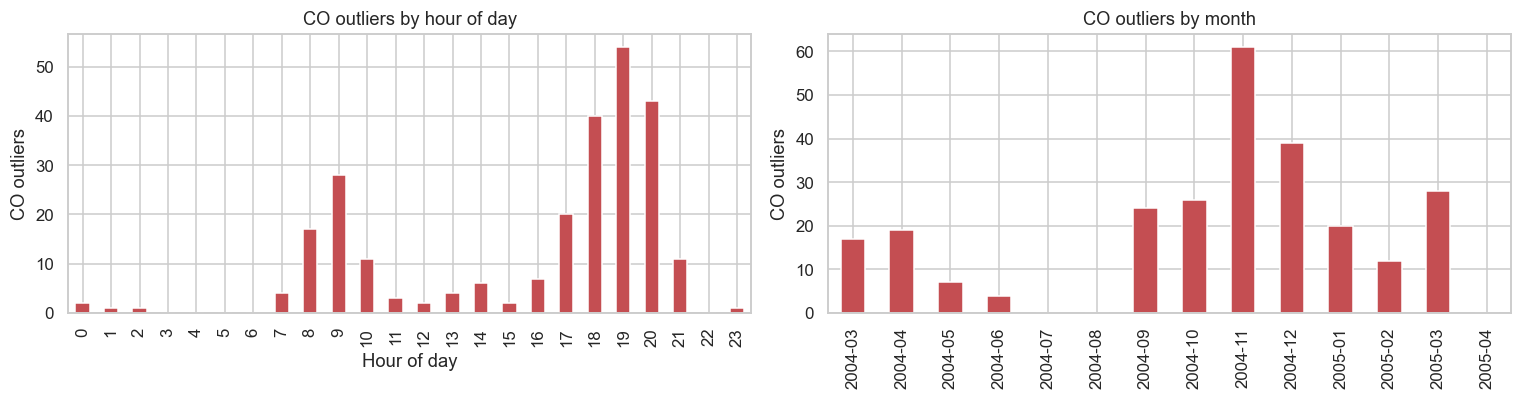

In [17]:
# What are the outliers? When they happen, and whether they are isolated spikes or longer episodes
co = df["CO_GT"]
co_outlier = iqr_outlier_mask(co)
neighbours_max = pd.concat([co.shift(1), co.shift(-1)], axis=1).max(axis=1)
isolated = co_outlier & (neighbours_max < co.quantile(.75))   # both neighbouring hours are ordinary
print(f"CO outliers that are isolated spikes (both neighbouring hours below the 75th percentile): "
      f"{isolated.sum()} of {co_outlier.sum()}")

s3_outlier = iqr_outlier_mask(df["S3_NOx"])
print(f"Mean NOx during S3_NOx outliers: {df.loc[s3_outlier, 'NOx_GT'].mean():.0f} {UNITS['NOx_GT']} "
      f"vs {df['NOx_GT'].mean():.0f} {UNITS['NOx_GT']} overall")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
co_outlier.groupby(df.index.hour).sum().plot.bar(ax=axes[0], color="#C44E52")
axes[0].set(xlabel="Hour of day", ylabel="CO outliers", title="CO outliers by hour of day")
co_outlier.groupby(df.index.to_period("M")).sum().plot.bar(ax=axes[1], color="#C44E52")
axes[1].set(xlabel="", ylabel="CO outliers", title="CO outliers by month")
plt.tight_layout(); plt.show()

**Decision: outliers are kept** (evidence in the cells above).
- **An IQR "outlier" here is the tail of a skewed distribution, not an error:** all but one lie above the upper fence, and the most skewed variables (NOx, CO) have the most.
- **CO outliers are real pollution episodes:** they concentrate in the rush hours (mostly 17–20 h, and 8–9 h) and in autumn and winter (61 in November 2004 alone, none in July or August), and only 1 of 257 is an isolated spike; the others belong to episodes lasting several hours.
- **S3_NOx outliers are the opposite: clean-air hours.** The S3 response rises as NOx falls, and during its outliers NOx averages 63 ppb vs 242 ppb overall. They are real readings too.
- **Removing them would hurt where it matters most:** a model trained without the CO outliers misses the real peaks (Section 5.3: on the test hours above the outlier threshold, MAE rises from 0.48 to 0.63 mg/m³).
- **How the models cope with them:** trees split on thresholds, so extreme values do not distort them; the SVR's loss grows only linearly with large errors; for the linear model the log target compresses the high tail. Scaling alone would not help, since the mean and standard deviation it uses are themselves sensitive to outliers.

### 3.7 Feature engineering

In [18]:
for d in (df, df_eda):
    d["hour"] = d.index.hour
    d["dayofweek"] = d.index.dayofweek          # 0 = Monday
    d["is_weekend"] = (d["dayofweek"] >= 5).astype(int)
    d["month"] = d.index.month
    d["season"] = d["month"].map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                                  6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"})
    d["day_name"] = d.index.day_name()

df.to_csv("airquality_clean.csv")
print("Clean dataset saved -> airquality_clean.csv", df.shape)
df.head()

Clean dataset saved -> airquality_clean.csv (8991, 21)


,CO_GT,S1_CO,C6H6_GT,S2_NMHC,NOx_GT,S3_NOx,NO2_GT,S4_NO2,S5_O3,T,...,AH,CO_GT_is_real,NOx_GT_is_real,NO2_GT_is_real,hour,dayofweek,is_weekend,month,season,day_name
Datetime,,,,,,,,,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,...,0.7578,True,True,True,18,2,0,3,Spring,Wednesday
2004-03-10 19:00:00,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,...,0.7255,True,True,True,19,2,0,3,Spring,Wednesday
2004-03-10 20:00:00,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,...,0.7502,True,True,True,20,2,0,3,Spring,Wednesday
2004-03-10 21:00:00,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,...,0.7867,True,True,True,21,2,0,3,Spring,Wednesday
2004-03-10 22:00:00,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,...,0.7888,True,True,True,22,2,0,3,Spring,Wednesday


#### Summary: data wrangling
1. **Loading:** `;` separator and `,` decimals; 9,471 lines including 2 empty columns and 114 empty rows → 9,357 rows × 15 columns.
2. **Datetime index:** Date + Time strings parsed into a continuous hourly index, with no duplicated or missing timestamps.
3. **Missing values:** `-200` → NaN. NMHC_GT (90% missing) dropped; 366 hours of device failure removed.
4. **Reference values (CO, NOx, NO2, ~18% missing):** short gaps (≤ 3 consecutive missing hours) filled by time interpolation for the EDA only; models use real measurements only.
5. **Outliers (IQR rule):** kept. They are the natural tail of skewed variables (pollution episodes, and clean-air hours for S3), not measurement errors; removing them worsens the predictions of real peaks (Section 5.3).
6. **New features:** hour, day of week, weekend flag, month and season.
7. **Split:** chronological train/test (Section 5).

## 4. Exploratory Data Analysis

### 4.1 Descriptive statistics

In [19]:
df_eda[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CO_GT,7506.0,2.10,1.44,0.10,1.00,1.8,2.80,11.90
C6H6_GT,8991.0,10.08,7.45,0.10,4.40,8.2,14.00,63.70
NOx_GT,7708.0,236.87,204.95,2.00,93.00,173.0,315.00,1479.00
NO2_GT,7706.0,110.45,47.94,2.00,74.00,107.0,139.00,333.00
S1_CO,8991.0,1099.83,217.08,647.00,937.00,1063.0,1231.00,2040.00
S2_NMHC,8991.0,939.15,266.83,383.00,734.50,909.0,1116.00,2214.00
S3_NOx,8991.0,835.49,256.82,322.00,658.00,806.0,969.50,2683.00
S4_NO2,8991.0,1456.26,346.21,551.00,1227.00,1463.0,1674.00,2775.00
S5_O3,8991.0,1022.91,398.48,221.00,731.50,963.0,1273.50,2523.00
T,8991.0,18.32,8.83,-1.90,11.80,17.8,24.40,44.60


### 4.2 Histograms — distributions

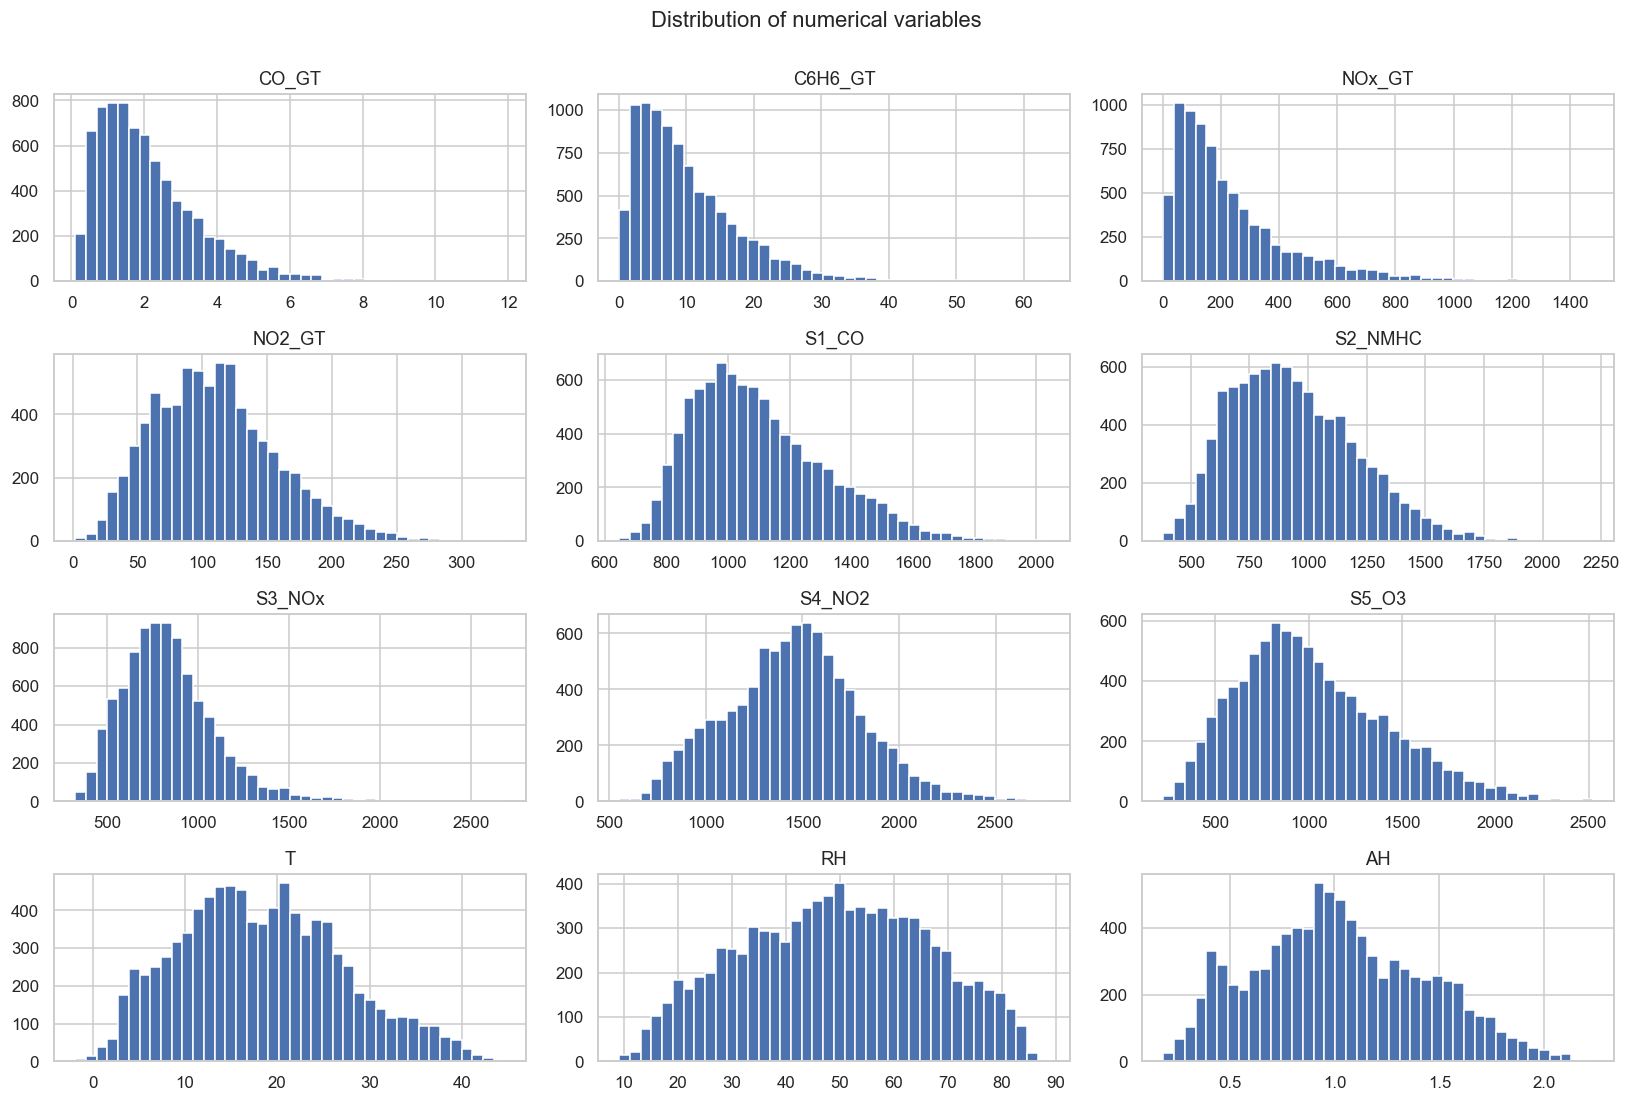

In [20]:
axes = df_eda[num_cols].hist(bins=40, figsize=(15, 10), color="#4C72B0", edgecolor="white")
plt.suptitle("Distribution of numerical variables", y=1.0); plt.tight_layout(); plt.show()

### 4.3 Box plot: CO by season

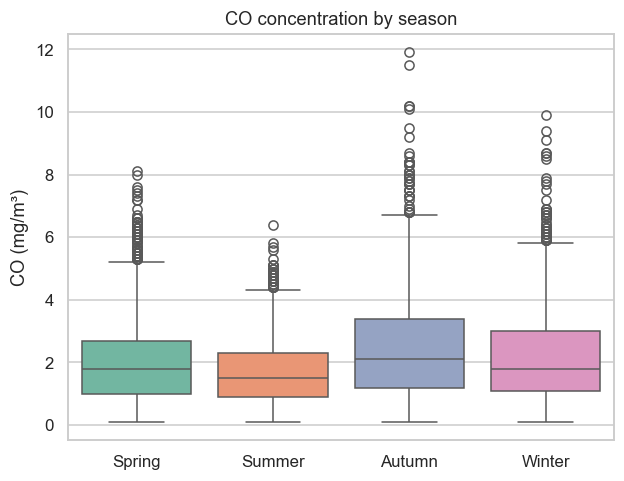

In [21]:
SEASON_ORDER = ["Spring", "Summer", "Autumn", "Winter"]
ax = sns.boxplot(data=df_eda, x="season", y="CO_GT", order=SEASON_ORDER, hue="season", palette="Set2", legend=False)
ax.set_title("CO concentration by season")
ax.set_xlabel(""); ax.set_ylabel(f"CO ({UNITS['CO_GT']})")
plt.show()

### 4.4 Bar chart: mean CO by day of week

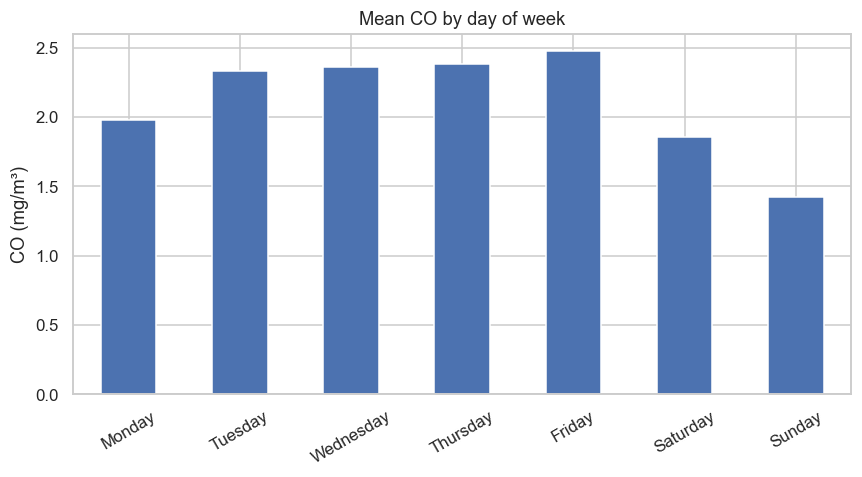

In [22]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ax = df_eda.groupby("day_name")["CO_GT"].mean().reindex(days).plot.bar(figsize=(8, 4.5), color="#4C72B0")
ax.set_title("Mean CO by day of week")
ax.set_ylabel(f"CO ({UNITS['CO_GT']})"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 4.5 Correlation heatmap

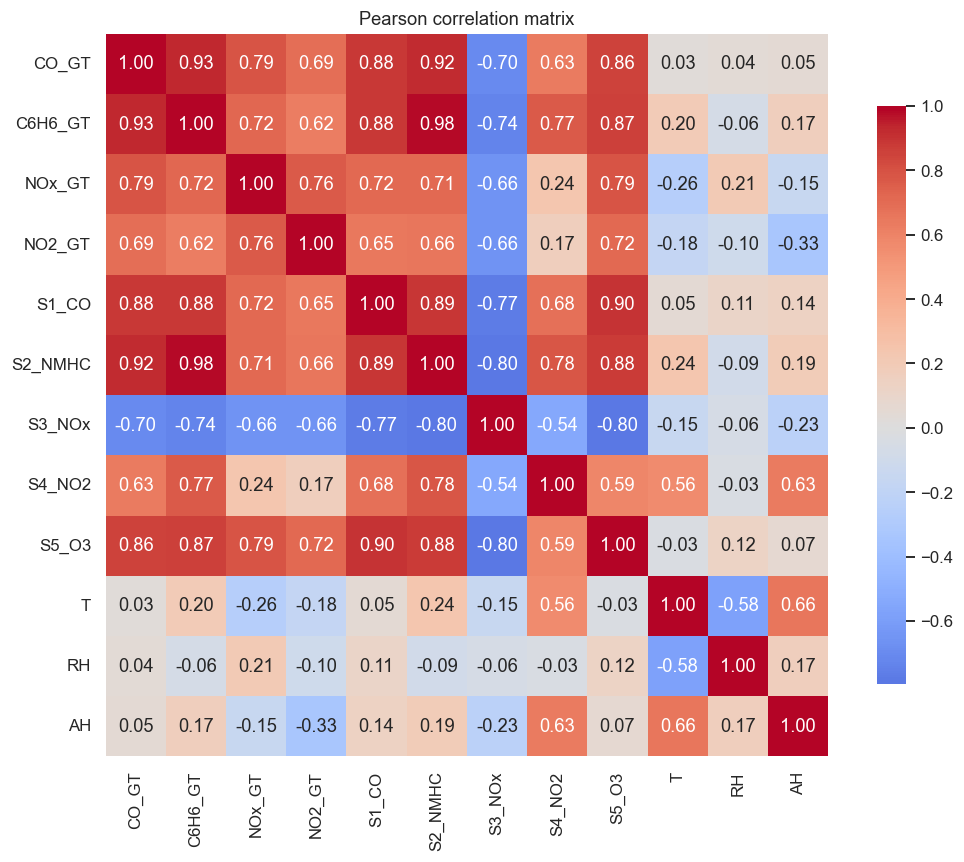

In [23]:
corr = df_eda[num_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Pearson correlation matrix"); plt.tight_layout(); plt.show()

### 4.6 Scatterplots — sensors vs ground truth

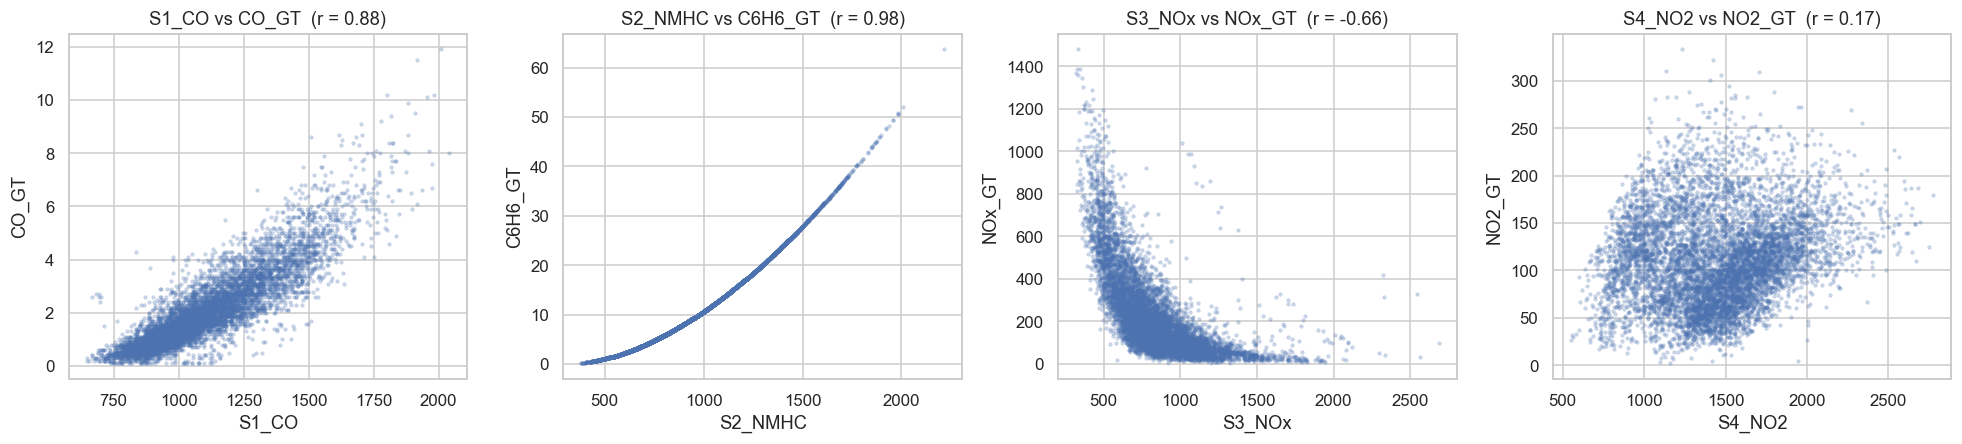

In [24]:
pairs = [("S1_CO", "CO_GT"), ("S2_NMHC", "C6H6_GT"), ("S3_NOx", "NOx_GT"), ("S4_NO2", "NO2_GT")]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=df_eda, x=x, y=y, s=6, alpha=.3, ax=ax, edgecolor=None)
    ax.set_title(f"{x} vs {y}  (r = {df_eda[[x, y]].corr().iloc[0, 1]:.2f})")
plt.tight_layout(); plt.show()

**Notable finding (hypothesis backed by two checks):** `C6H6_GT` vs `S2_NMHC` draws an almost perfect curve with no noise. The UCI description lists benzene as measured by the reference analyzer, but the two checks in the next cell suggest the published benzene values were **computed from the S2 sensor** rather than measured independently:
1. A degree-4 polynomial of S2 alone reproduces `C6H6_GT` with **R² ≈ 0.99998**.
2. `C6H6_GT` is missing in **exactly the 366 hours when the sensor device was down, and never otherwise**. The truly independent reference values (CO, NOx, NO2) have their own gaps, mostly outside device failures (≈1,600 hours each).

Consequence: we do not use benzene as a target (predicting it from S2 would be trivial and meaningless). We predict **CO_GT** instead.

In [25]:
# Two independent checks of the hypothesis "C6H6_GT is a function of the S2 sensor"
POLY_DEGREE = 4

# Check 1: how much of C6H6_GT does S2 alone explain?
pair = df[["S2_NMHC", "C6H6_GT"]].dropna()
coefs = np.polyfit(pair["S2_NMHC"], pair["C6H6_GT"], deg=POLY_DEGREE)
r2_poly = r2_score(pair["C6H6_GT"], np.polyval(coefs, pair["S2_NMHC"]))
print(f"Check 1: degree-{POLY_DEGREE} polynomial of S2 explains C6H6_GT with R² = {r2_poly:.5f}")

# Check 2: do the reference values go missing together with the sensor device?
# Uses the raw file because the device-down rows have already been removed from df.
raw_rows = raw.dropna(subset=["Date"])
device_down = raw_rows["PT08.S1(CO)"] == MISSING_CODE
gt_raw_cols = {"CO(GT)": "CO_GT", "C6H6(GT)": "C6H6_GT", "NOx(GT)": "NOx_GT", "NO2(GT)": "NO2_GT"}
overlap = pd.DataFrame({
    gt_name: {"missing_total": (raw_rows[raw_col] == MISSING_CODE).sum(),
              "missing_while_device_down": ((raw_rows[raw_col] == MISSING_CODE) & device_down).sum(),
              "missing_while_device_working": ((raw_rows[raw_col] == MISSING_CODE) & ~device_down).sum()}
    for raw_col, gt_name in gt_raw_cols.items()
}).T
print(f"Check 2: device down for {device_down.sum()} hours")
overlap

Check 1: degree-4 polynomial of S2 explains C6H6_GT with R² = 0.99998
Check 2: device down for 366 hours


,missing_total,missing_while_device_down,missing_while_device_working
CO_GT,1683,36,1647
C6H6_GT,366,366,0
NOx_GT,1639,44,1595
NO2_GT,1642,44,1598


**S4_NO2 vs NO2:** over the whole period S4 hardly correlates with NO2 (r = 0.17). The next cell checks whether S4 does not respond to NO2, or whether something else moves its level.

In [26]:
# Does S4 respond to NO2? Compare the correlation over the whole period with the correlation inside each month.
MIN_PAIRS_PER_MONTH = 200   # months with fewer valid hours are left out (April 2005 has 4 days)

def partial_corr(data, x, y, controls):
    """Correlation between x and y after removing the linear effect of `controls` from both."""
    d = data[[x, y] + controls].dropna()
    Z = np.column_stack([np.ones(len(d)), d[controls].to_numpy()])

    def residual(v):
        return v - Z @ np.linalg.lstsq(Z, v, rcond=None)[0]

    return np.corrcoef(residual(d[x].to_numpy()), residual(d[y].to_numpy()))[0, 1]

pairs_s4 = df_eda[["S4_NO2", "NO2_GT"]].dropna()
month = pairs_s4.index.to_period("M")
monthly = pd.DataFrame({
    "r(S4, NO2)": pairs_s4.groupby(month).apply(lambda m: m["S4_NO2"].corr(m["NO2_GT"])),
    "mean S4": pairs_s4.groupby(month)["S4_NO2"].mean(),
    f"mean NO2 ({UNITS['NO2_GT']})": pairs_s4.groupby(month)["NO2_GT"].mean(),
    "n hours": pairs_s4.groupby(month).size(),
})
monthly = monthly[monthly["n hours"] >= MIN_PAIRS_PER_MONTH]

print(f"Whole period:   r(S4, NO2) = {pairs_s4['S4_NO2'].corr(pairs_s4['NO2_GT']):.2f}")
print(f"Within a month: r between {monthly['r(S4, NO2)'].min():.2f} and {monthly['r(S4, NO2)'].max():.2f} "
      f"(median {monthly['r(S4, NO2)'].median():.2f})")
print(f"Whole period, controlling for T and AH: partial r = {partial_corr(df_eda, 'S4_NO2', 'NO2_GT', ['T', 'AH']):.2f}")
monthly.round(2)

Whole period:   r(S4, NO2) = 0.17
Within a month: r between 0.46 and 0.84 (median 0.70)
Whole period, controlling for T and AH: partial r = 0.54


,"r(S4, NO2)",mean S4,mean NO2 (µg/m³),n hours
Datetime,,,,
2004-03,0.84,1572.07,101.05,510
2004-04,0.82,1605.83,94.41,479
2004-05,0.70,1605.84,91.46,625
2004-06,0.76,1726.29,93.46,641
2004-07,0.70,1643.82,102.07,743
2004-08,0.50,1597.59,67.77,474
2004-09,0.70,1545.73,106.05,466
2004-10,0.81,1692.50,88.10,404
2004-11,0.46,1379.13,120.54,687


#### Interpretation: S4_NO2
- **S4 does respond to NO2:** within each month r is between 0.46 and 0.84 (median 0.70), and over the whole period the correlation after removing temperature and humidity is 0.54.
- **Its baseline is the problem:** the monthly mean of S4 stays between 1,550 and 1,730 from March to October 2004, then falls to 1,058 in February 2005, while NO2 does the opposite (156 µg/m³ in February vs 68 in August). The two yearly trends cancel the hour-to-hour agreement, so over the year r is only 0.17.
- **Consequence:** S4 is kept as an input, but it is the clearest case of sensor drift in the data, and the test period starts at its lowest level.

### 4.7 Line plot: average daily profile of CO

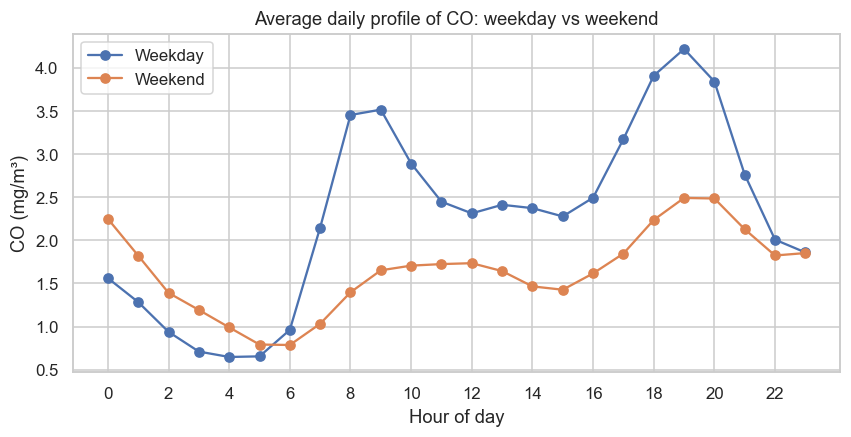

In [27]:
hourly = df_eda.groupby(["is_weekend", "hour"])["CO_GT"].mean().unstack(0)
hourly.columns = ["Weekday", "Weekend"]
hourly.plot(figsize=(9, 4), marker="o")
plt.title("Average daily profile of CO: weekday vs weekend")
plt.ylabel(f"CO ({UNITS['CO_GT']})"); plt.xlabel("Hour of day")
plt.xticks(range(0, 24, 2)); plt.show()

### 4.8 Interactive visual analytics (Plotly)

In [28]:
# Interactive time series: one row per pollutant (different units), zoom with the range slider
POLLUTANTS = ["CO_GT", "NOx_GT", "NO2_GT"]
daily = df_eda[POLLUTANTS].resample("D").mean()
daily_long = (daily.reset_index()
              .melt(id_vars="Datetime", var_name="Pollutant", value_name="Value"))
daily_long["Pollutant"] = daily_long["Pollutant"].map(lambda p: f"{p.replace('_GT', '')} ({UNITS[p]})")

fig = px.line(daily_long, x="Datetime", y="Value", color="Pollutant", facet_row="Pollutant", height=650,
              title="Daily pollutant concentrations (interactive: zoom with the slider)")
fig.update_yaxes(matches=None, title_text="")                        # independent scale per pollutant
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))  # facet label = "CO (mg/m³)"
fig.update_xaxes(rangeslider_visible=True, row=1, col=1)              # row 1 is the bottom panel
fig.update_layout(showlegend=False)
fig.show()

In [29]:
# Hour x day-of-week heatmap: the 'traffic fingerprint'
pivot = df_eda.pivot_table(index="day_name", columns="hour", values="CO_GT", aggfunc="mean").reindex(days)
fig = px.imshow(pivot, aspect="auto", color_continuous_scale="Reds",
                labels=dict(x="Hour of day", y="", color="CO mg/m³"),
                title="Mean CO by hour and day of week")
fig.show()

In [30]:
# Interactive daily profile by month: does the shape of the day change over the year?
# Months are labelled year-month because March and April appear in both 2004 and 2005.
Y_MARGIN = 1.05   # headroom above the highest value so every frame shares the same y-axis
profile = (df_eda.assign(month_label=df_eda.index.strftime("%Y-%m"),
                         day_type=df_eda["is_weekend"].map({0: "Weekday", 1: "Weekend"}))
           .groupby(["month_label", "day_type", "hour"])["CO_GT"].mean()
           .rename("CO").reset_index())

fig = px.line(profile, x="hour", y="CO", color="day_type", line_dash="day_type", animation_frame="month_label",
              range_y=[0, profile["CO"].max() * Y_MARGIN],
              labels={"hour": "Hour of day", "CO": f"CO ({UNITS['CO_GT']})", "day_type": "", "month_label": "Month"},
              title="Average daily profile of CO by month (move the slider or press play)")
fig.update_xaxes(dtick=2)
fig.show()

#### Summary: exploratory data analysis
- Pollutant distributions are **right-skewed** (many low values, a few high peaks), so the IQR "outliers" are real pollution peaks.
- **Traffic fingerprint:** on weekdays CO peaks twice, at 8–9 h (≈3.5 mg/m³) and at 19 h (≈4.2 mg/m³). Weekends have no morning peak (1.4 mg/m³ at 8 h), and Sunday is the cleanest day (mean 1.42 mg/m³ vs 2.3–2.5 from Tuesday to Friday).
- **Night-time gaps (Section 3.4):** the reference analyzer misses CO most often at 4 h (54% of hours vs 18% overall), so the night-time part of the daily profile rests on fewer days, and the raw data slightly overstate the average CO level.
- **The daily pattern changes shape over the year (interactive profile, Section 4.8):** the weekday morning peak is the higher one only from May to August 2004; in every other month the evening peak dominates, by up to 2.4 mg/m³ in November (3.05 mg/m³ at 8 h vs 5.44 at 19 h). The annual average profile in Section 4.7 blends both shapes. (April 2005 contains only 4 days and is not reliable.)
- **Seasonality:** autumn has the highest CO (mean 2.49 mg/m³; October–November 2.66), then winter (2.19), spring (2.05) and summer (1.69). August is the minimum (1.25), consistent with the holiday drop in traffic.
- **How well a cheap sensor tracks the reference depends on the sensor:**
  - CO is tracked closely by S2_NMHC (r = 0.92), S1_CO (r = 0.88) and S5_O3 (r = 0.86), so predicting CO is feasible.
  - S3_NOx is negatively correlated with NOx (r = −0.66): its response falls as NOx rises.
  - S4_NO2 follows NO2 within each month (median r = 0.70), but its baseline drifts down through the winter while NO2 rises, so over the whole year r is only 0.17.
- **The hydrocarbon sensor S2 tracks CO better than the CO sensor S1** (0.92 vs 0.88): traffic emits CO and hydrocarbons together. S1 and S2 are also strongly correlated with each other (r = 0.89), which matters when reading SHAP.
- `C6H6_GT` appears to be computed from S2 (R² ≈ 0.99998, missing in exactly the device-down hours), so it is excluded as a target.

## 5. Predictive analysis — Regression of `CO_GT`

**Task:** regression, predicting the certified CO concentration from the low-cost device.
- **Target:** `CO_GT` (only rows with a real measurement).
- **Features:** 5 sensors + T, RH, AH + hour, day of week, weekend flag. Other GT columns are **excluded** (they come from the expensive analyzer, so using them would be data leakage in a real deployment). Month is excluded (leakage test in Section 7.3).
- **Split:** **chronological** at 1 February 2005 (train March 2004 – January 2005, test February – April 2005, about 81/19), because the data is a time series with sensor drift. Cutting at a month boundary keeps every day entirely on one side. A random split would leak future information.
- **Baselines:** every model must beat (1) predicting the training mean and (2) the classic calibration a technician would do: a straight line from the CO sensor S1 alone. Without these, an R² has nothing to be compared with.
- **Preprocessing depends on the model family (Section 5.0):** trees use the features as they are; linear and distance-based models get scaled sensors and **one-hot encoded calendar features**, and the linear model is also tried with a **log-transformed target**.

In [31]:
TARGET = "CO_GT"   # change to "NOx_GT" or "NO2_GT" to try other targets
FEATURES = SENSOR_COLS + WEATHER_COLS + ["hour", "dayofweek", "is_weekend"]
TEST_START = "2005-02-01"   # chronological cut at a month boundary: train Mar 2004 - Jan 2005, test Feb - Apr 2005

data = df[df[f"{TARGET}_is_real"]].copy() if f"{TARGET}_is_real" in df else df.dropna(subset=[TARGET]).copy()
train, test = data[data.index < TEST_START], data[data.index >= TEST_START]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {train.index.min():%Y-%m-%d} -> {train.index.max():%Y-%m-%d}  ({len(train)} rows, {len(train) / len(data):.0%})")
print(f"Test : {test.index.min():%Y-%m-%d} -> {test.index.max():%Y-%m-%d}  ({len(test)} rows, {len(test) / len(data):.0%})")

Train: 2004-03-10 -> 2005-01-31  (5948 rows, 81%)
Test : 2005-02-01 -> 2005-04-04  (1396 rows, 19%)


### 5.0 Preprocessing for linear and distance-based models
- **Calendar encoding:** as a plain number, `hour` makes a linear model treat 23 h as far from 0 h and CO as growing through the day. CO has two daily peaks instead, so each hour gets its own one-hot column.
- **Hour × day type:** weekends have a different daily shape, not just a lower level (Section 4.7), so we encode the 48 combinations of hour and weekday/weekend. Day-of-week dummies are not added on top, since they would encode the weekend twice.
- **Log target:** CO is right-skewed; predicting log(1 + CO) makes the model care about relative rather than absolute errors.
- **Who uses it:** linear regression, KNN and SVR (its RBF kernel is based on distances). **Trees are left unchanged:** they can split `hour` at any point, and scaling does not affect them.

In [32]:
HOURS_PER_DAY = 24
NUMERIC_INPUTS = SENSOR_COLS + WEATHER_COLS

def hour_daytype_code(X):
    """Map (hour, is_weekend) to one category per hour and day type: 0-23 weekday, 24-47 weekend."""
    return np.asarray(X["hour"] + HOURS_PER_DAY * X["is_weekend"]).reshape(-1, 1)

def make_linear_preprocessor():
    """Scaled sensors and weather + one-hot (hour x day type). Unused columns (dayofweek) are dropped."""
    hour_daytype = make_pipeline(FunctionTransformer(hour_daytype_code),
                                 OneHotEncoder(drop="first", handle_unknown="ignore"))
    return ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC_INPUTS),
        ("hour_daytype", hour_daytype, ["hour", "is_weekend"]),
    ])

def log_target(estimator):
    """Fit on log(1 + CO) and convert predictions back to mg/m³."""
    return TransformedTargetRegressor(regressor=estimator, func=np.log1p, inverse_func=np.expm1)

# Sanity check: 8 scaled numeric inputs + 47 hour x day-type dummies (48 categories, first one dropped)
print("Linear design matrix shape:", make_linear_preprocessor().fit_transform(X_train).shape)

Linear design matrix shape: (5948, 55)


#### Models compared
We compare models from different families, each making a different assumption about how the sensors relate to CO:

| Model | Family | Why it is included |
|---|---|---|
| Training mean | Naive baseline | The floor: R² is defined against it |
| S1 only, linear | Simple linear regression | How the CO sensor would be calibrated on its own |
| Linear Regression | Multiple linear regression | Global and interpretable; three variants show the effect of each preprocessing step |
| KNN | Instance-based | Predicts from similar past hours, with no assumed shape |
| Decision Tree | Single tree | The simplest tree model; the baseline that tree ensembles improve on |
| Random Forest | Tree ensemble (bagging) | Captures non-linearities and interactions; robust, needs little tuning |
| XGBoost | Tree ensemble (boosting) | Not covered in the course: added as the standard strong model for tabular data |
| SVR (SVM with RBF kernel) | Kernel method | The kernel trick gives a smooth non-linear function, between the linear model and the trees |

Logistic regression, also covered in the course, is not used because it is a classification model.

In [33]:
N_CV_SPLITS = 4
tscv = TimeSeriesSplit(n_splits=N_CV_SPLITS)   # every fold trains on the past and validates on the next block
CV_SCORING = "neg_root_mean_squared_error"
METRIC_COLS = ["MAE", "MSE", "RMSE", "R2"]

def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

def cv_rmse(estimator):
    """Mean RMSE over the time-series CV folds. Uses the training period only."""
    scores = cross_val_score(estimator, X_train, y_train, cv=tscv, scoring=CV_SCORING, n_jobs=-1)
    return -scores.mean()

S1_ONLY = ColumnTransformer([("s1", "passthrough", ["S1_CO"])])
models = {
    "Baseline: training mean": DummyRegressor(strategy="mean"),
    "Baseline: S1 sensor only (linear calibration)": make_pipeline(S1_ONLY, LinearRegression()),
    "Linear Regression (calendar as numbers)": make_pipeline(StandardScaler(), LinearRegression()),
    "Linear Regression (encoded)": make_pipeline(make_linear_preprocessor(), LinearRegression()),
    "Linear Regression (encoded + log target)": log_target(make_pipeline(make_linear_preprocessor(), LinearRegression())),
    "KNN (k=10, encoded)": make_pipeline(make_linear_preprocessor(), KNeighborsRegressor(n_neighbors=10)),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=RANDOM_STATE),
    "SVR (RBF kernel)": make_pipeline(make_linear_preprocessor(), SVR(kernel="rbf")),
}
results, preds, fitted = [], {}, {}
for name, m in models.items():
    cv = cv_rmse(m)
    m.fit(X_train, y_train)
    fitted[name] = m
    preds[name] = m.predict(X_test)
    results.append(evaluate(name, y_test, preds[name]) | {"CV_RMSE": cv})
pd.DataFrame(results).set_index("Model")[["CV_RMSE"] + METRIC_COLS].round(3)

,CV_RMSE,MAE,MSE,RMSE,R2
Model,,,,,
Baseline: training mean,1.479,1.056,1.717,1.310,-0.023
Baseline: S1 sensor only (linear calibration),0.713,0.559,0.530,0.728,0.685
Linear Regression (calendar as numbers),0.568,0.341,0.234,0.484,0.861
Linear Regression (encoded),0.546,0.323,0.211,0.460,0.874
Linear Regression (encoded + log target),0.519,0.270,0.193,0.440,0.885
"KNN (k=10, encoded)",0.597,0.371,0.267,0.517,0.841
Decision Tree,0.627,0.575,0.737,0.858,0.561
Random Forest,0.474,0.346,0.267,0.517,0.841
XGBoost,0.485,0.349,0.256,0.506,0.848


### 5.1 Hyperparameter tuning (GridSearchCV with time-series cross-validation)

In [34]:
dt_grid = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                       {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [1, 5, 20, 50]},
                       cv=tscv, scoring=CV_SCORING, n_jobs=-1)
dt_grid.fit(X_train, y_train)

rf_grid = GridSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                       {"n_estimators": [200, 400], "max_depth": [None, 15], "min_samples_leaf": [1, 5]},
                       cv=tscv, scoring=CV_SCORING, n_jobs=-1)
rf_grid.fit(X_train, y_train)

xgb_grid = GridSearchCV(XGBRegressor(random_state=RANDOM_STATE),
                        {"n_estimators": [300, 600], "max_depth": [3, 5], "learning_rate": [0.03, 0.08], "subsample": [0.8, 1.0]},
                        cv=tscv, scoring=CV_SCORING, n_jobs=-1)
xgb_grid.fit(X_train, y_train)

knn_grid = GridSearchCV(make_pipeline(make_linear_preprocessor(), KNeighborsRegressor()),
                        {"kneighborsregressor__n_neighbors": [5, 10, 20, 40], "kneighborsregressor__weights": ["uniform", "distance"]},
                        cv=tscv, scoring=CV_SCORING, n_jobs=-1)
knn_grid.fit(X_train, y_train)

# SVR: C = how strongly errors are penalised, gamma = how far the influence of each training hour reaches
# (small gamma = smoother function), epsilon = width of the error band that is not penalised at all
svr_grid = GridSearchCV(make_pipeline(make_linear_preprocessor(), SVR(kernel="rbf")),
                        {"svr__C": [3, 10, 30, 100], "svr__gamma": [0.0003, 0.001, 0.003, 0.01], "svr__epsilon": [0.01, 0.05, 0.1]},
                        cv=tscv, scoring=CV_SCORING, n_jobs=-1)
svr_grid.fit(X_train, y_train)

for name, g in [("Decision Tree (tuned)", dt_grid), ("Random Forest (tuned)", rf_grid), ("XGBoost (tuned)", xgb_grid),
                ("KNN (tuned, encoded)", knn_grid), ("SVR (RBF kernel, tuned)", svr_grid)]:
    print(name, g.best_params_, "CV RMSE:", round(-g.best_score_, 3))
    fitted[name] = g.best_estimator_
    preds[name] = g.best_estimator_.predict(X_test)
    results.append(evaluate(name, y_test, preds[name]) | {"CV_RMSE": -g.best_score_})

# Does the log target also help the tuned XGBoost? Same hyperparameters, scored with the same CV.
name = "XGBoost (tuned) + log target"
xgb_log = log_target(XGBRegressor(**xgb_grid.best_params_, random_state=RANDOM_STATE))
cv = cv_rmse(xgb_log)
fitted[name] = xgb_log.fit(X_train, y_train)
preds[name] = xgb_log.predict(X_test)
results.append(evaluate(name, y_test, preds[name]) | {"CV_RMSE": cv})

# Model selection uses ONLY the CV score (training period).
# The test period is used once, to report the performance of the selected model.
res = pd.DataFrame(results).set_index("Model")[["CV_RMSE"] + METRIC_COLS].sort_values("CV_RMSE")
best_name = res["CV_RMSE"].idxmin()
print("\nSelected model (lowest CV RMSE):", best_name)
res.round(3)

Decision Tree (tuned) {'max_depth': 8, 'min_samples_leaf': 20} CV RMSE: 0.532
Random Forest (tuned) {'max_depth': 15, 'min_samples_leaf': 5, 'n_estimators': 400} CV RMSE: 0.473
XGBoost (tuned) {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8} CV RMSE: 0.467
KNN (tuned, encoded) {'kneighborsregressor__n_neighbors': 10, 'kneighborsregressor__weights': 'distance'} CV RMSE: 0.594
SVR (RBF kernel, tuned) {'svr__C': 30, 'svr__epsilon': 0.01, 'svr__gamma': 0.001} CV RMSE: 0.46

Selected model (lowest CV RMSE): SVR (RBF kernel, tuned)


,CV_RMSE,MAE,MSE,RMSE,R2
Model,,,,,
"SVR (RBF kernel, tuned)",0.460,0.280,0.187,0.432,0.889
XGBoost (tuned),0.467,0.301,0.213,0.461,0.873
Random Forest (tuned),0.473,0.326,0.237,0.487,0.859
Random Forest,0.474,0.346,0.267,0.517,0.841
XGBoost (tuned) + log target,0.484,0.313,0.224,0.474,0.866
XGBoost,0.485,0.349,0.256,0.506,0.848
Linear Regression (encoded + log target),0.519,0.270,0.193,0.440,0.885
Decision Tree (tuned),0.532,0.369,0.293,0.541,0.826
Linear Regression (encoded),0.546,0.323,0.211,0.460,0.874


In [35]:
# Per-fold CV RMSE: is a model consistently good, or good on average only?
FOLD_MODELS = ["SVR (RBF kernel, tuned)", "XGBoost (tuned)", "Linear Regression (encoded + log target)",
               "Linear Regression (encoded)", "Linear Regression (calendar as numbers)"]
fold_periods = [f"{X_train.index[val[0]]:%d %b} to {X_train.index[val[-1]]:%d %b %Y}" for _, val in tscv.split(X_train)]
fold_rmse = pd.DataFrame({
    name: -cross_val_score(fitted[name], X_train, y_train, cv=tscv, scoring=CV_SCORING, n_jobs=-1)
    for name in FOLD_MODELS
}, index=fold_periods)
fold_rmse.round(3)

,"SVR (RBF kernel, tuned)",XGBoost (tuned),Linear Regression (encoded + log target),Linear Regression (encoded),Linear Regression (calendar as numbers)
13 May to 10 Jul 2004,0.295,0.315,0.385,0.337,0.381
10 Jul to 25 Sep 2004,0.365,0.280,0.269,0.519,0.523
25 Sep to 30 Nov 2004,0.552,0.546,0.769,0.653,0.680
30 Nov to 31 Jan 2005,0.629,0.727,0.652,0.673,0.689


In [36]:
# Why does the log-target linear model fail in the autumn fold? Refit it on that fold and inspect its errors.
AUTUMN_FOLD = 2        # third fold (0-based)
WORST_SHARE = 0.01     # share of hours with the largest errors
LOG_LR = "Linear Regression (encoded + log target)"

train_idx, val_idx = list(tscv.split(X_train))[AUTUMN_FOLD]
fold_model = clone(fitted[LOG_LR]).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
val_true = y_train.iloc[val_idx].to_numpy()
val_pred = fold_model.predict(X_train.iloc[val_idx])
sq_err = np.sort((val_pred - val_true) ** 2)
n_worst = int(len(sq_err) * WORST_SHARE)
print(f"Autumn fold ({fold_periods[AUTUMN_FOLD]}): highest prediction {val_pred.max():.1f} {UNITS[TARGET]}, "
      f"highest observed value {val_true.max():.1f} {UNITS[TARGET]}")
print(f"The worst {WORST_SHARE:.0%} of hours produce {sq_err[-n_worst:].sum() / sq_err.sum():.0%} of the squared error")

Autumn fold (25 Sep to 30 Nov 2004): highest prediction 16.7 mg/m³, highest observed value 11.9 mg/m³
The worst 1% of hours produce 50% of the squared error


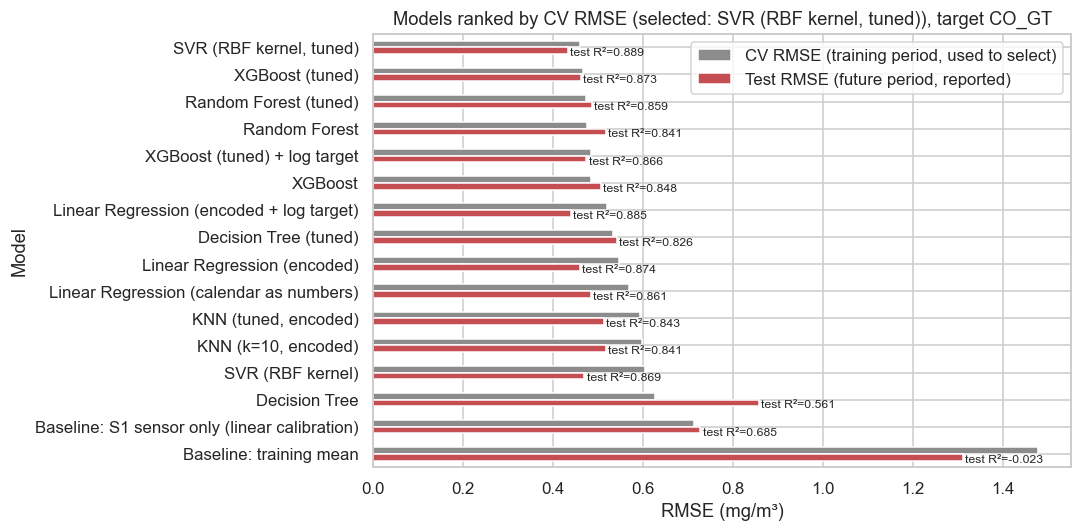

In [37]:
ax = (res[["CV_RMSE", "RMSE"]]
      .rename(columns={"CV_RMSE": "CV RMSE (training period, used to select)",
                       "RMSE": "Test RMSE (future period, reported)"})
      .plot.barh(figsize=(10, 5), color=["#8C8C8C", "#C44E52"]))
ax.invert_yaxis()
ax.set_xlabel(f"RMSE ({UNITS[TARGET]})")
ax.set_title(f"Models ranked by CV RMSE (selected: {best_name}), target {TARGET}")
for i, (rmse, r2) in enumerate(zip(res["RMSE"], res["R2"])):
    ax.text(rmse + 0.005, i + 0.2, f"test R²={r2:.3f}", fontsize=8, va="center")
plt.tight_layout(); plt.show()

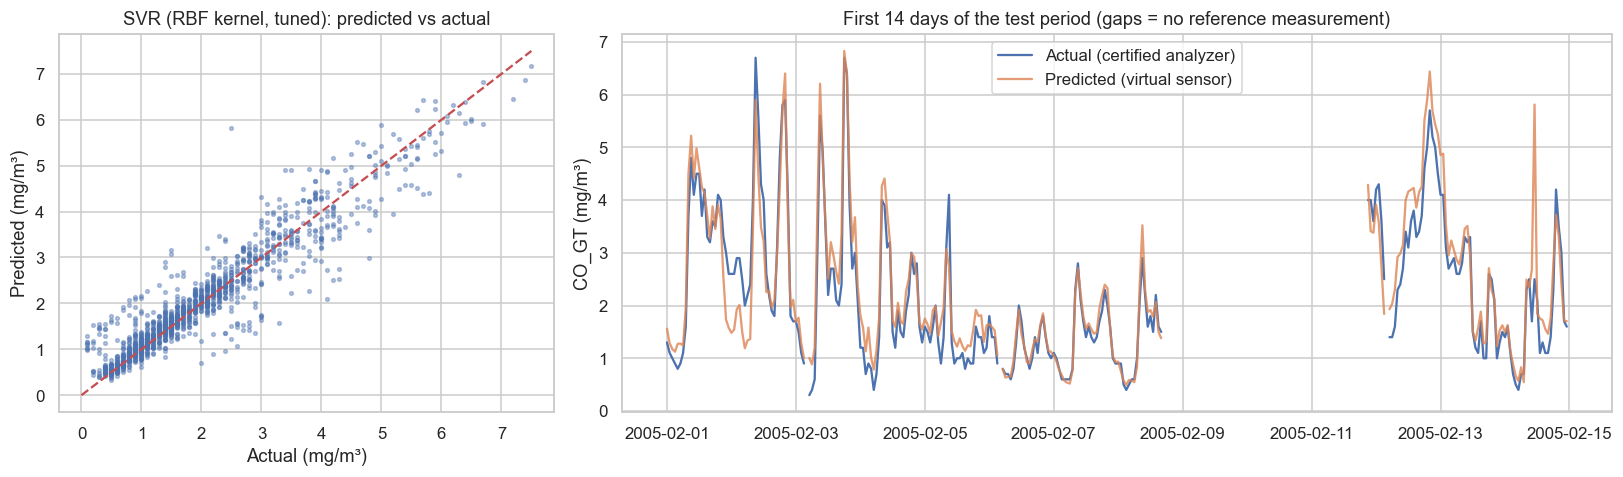

In [38]:
# best_name was chosen in the tuning cell by CV RMSE, never by the test score
y_best = preds[best_name]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 2]})
axes[0].scatter(y_test, y_best, s=6, alpha=.4)
lim = [0, max(y_test.max(), y_best.max())]
axes[0].plot(lim, lim, "r--")
axes[0].set_xlabel(f"Actual ({UNITS[TARGET]})"); axes[0].set_ylabel(f"Predicted ({UNITS[TARGET]})")
axes[0].set_title(f"{best_name}: predicted vs actual")

DAYS_SHOWN = 14
window_start = test.index[0]
# Full hourly grid over the window: hours without a reference measurement stay empty instead of being bridged
hours = pd.date_range(window_start, window_start + pd.Timedelta(days=DAYS_SHOWN), freq="h", inclusive="left")
comparison = pd.DataFrame({"actual": y_test, "predicted": y_best}, index=test.index).reindex(hours)
axes[1].plot(comparison.index, comparison["actual"], label="Actual (certified analyzer)")
axes[1].plot(comparison.index, comparison["predicted"], label="Predicted (virtual sensor)", alpha=.8)
axes[1].set_ylabel(f"{TARGET} ({UNITS[TARGET]})")
axes[1].legend(); axes[1].set_title(f"First {DAYS_SHOWN} days of the test period (gaps = no reference measurement)")
plt.tight_layout(); plt.show()

### 5.2 Extrapolation or shift? Comparing train and test inputs

In [39]:
# Are test inputs outside the training range (extrapolation) or inside it but shifted (covariate shift)?
INPUT_COLS = SENSOR_COLS + WEATHER_COLS
shift = pd.DataFrame({
    "train_mean": X_train[INPUT_COLS].mean(),
    "test_mean": X_test[INPUT_COLS].mean(),
    "pct_test_outside_train_range": [
        ((X_test[c] < X_train[c].min()) | (X_test[c] > X_train[c].max())).mean() * 100 for c in INPUT_COLS],
})
shift["mean_change_pct"] = (shift["test_mean"] / shift["train_mean"] - 1) * 100
shift.round(1).sort_values("mean_change_pct")

,train_mean,test_mean,pct_test_outside_train_range,mean_change_pct
T,19.4,10.9,2.1,-43.6
AH,1.1,0.7,0.3,-38.1
S4_NO2,1515.4,1143.6,1.1,-24.5
S3_NOx,844.9,750.4,0.0,-11.2
S2_NMHC,966.9,863.1,0.1,-10.7
S5_O3,1043.4,1043.9,0.4,0.0
S1_CO,1110.0,1113.1,0.0,0.3
RH,48.8,50.2,0.0,3.0


### 5.3 Robustness of the selected model
Two checks on the selected model: **residual diagnostics** (is the error unbiased, does it grow with the CO level, are some hours worse?) and **sensitivity to outliers** (would removing the IQR outliers of the target, as is sometimes done, help or hurt?).

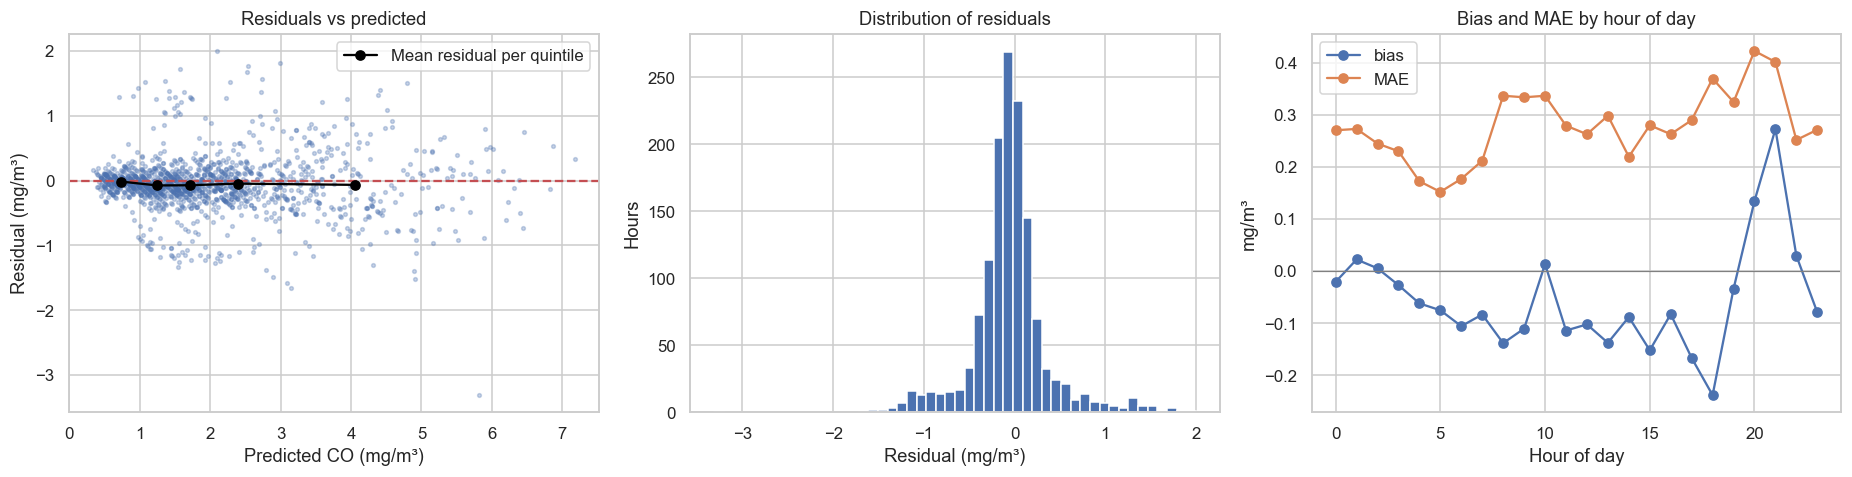

Overall bias (mean residual): -0.056 mg/m³


,hours,bias,MAE
level,,,
"(0.332, 1.025]",280,-0.016,0.130
"(1.025, 1.479]",279,-0.076,0.235
"(1.479, 2.012]",279,-0.073,0.286
"(2.012, 2.942]",279,-0.048,0.304
"(2.942, 7.175]",279,-0.067,0.444


In [40]:
# Residual diagnostics of the selected model on the test period (residual = actual - predicted)
N_LEVEL_BINS = 5   # quintiles of the predicted CO
diag = pd.DataFrame({"actual": y_test, "predicted": preds[best_name]}, index=test.index)
diag["residual"] = diag["actual"] - diag["predicted"]
diag["level"] = pd.qcut(diag["predicted"], N_LEVEL_BINS)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(diag["predicted"], diag["residual"], s=6, alpha=.3)
axes[0].axhline(0, color="#C44E52", ls="--")
binned = diag.groupby("level", observed=True)[["predicted", "residual"]].mean()
axes[0].plot(binned["predicted"], binned["residual"], color="black", marker="o", label="Mean residual per quintile")
axes[0].set(xlabel=f"Predicted CO ({UNITS[TARGET]})", ylabel=f"Residual ({UNITS[TARGET]})", title="Residuals vs predicted")
axes[0].legend()
axes[1].hist(diag["residual"], bins=50, color="#4C72B0")
axes[1].set(xlabel=f"Residual ({UNITS[TARGET]})", ylabel="Hours", title="Distribution of residuals")
by_hour = diag.groupby(diag.index.hour)["residual"].agg(bias="mean", MAE=lambda r: r.abs().mean())
by_hour.plot(ax=axes[2], marker="o")
axes[2].axhline(0, color="grey", lw=.8)
axes[2].set(xlabel="Hour of day", ylabel=UNITS[TARGET], title="Bias and MAE by hour of day")
plt.tight_layout(); plt.show()

print(f"Overall bias (mean residual): {diag['residual'].mean():+.3f} {UNITS[TARGET]}")
diag.groupby("level", observed=True)["residual"].agg(hours="size", bias="mean", MAE=lambda r: r.abs().mean()).round(3)

In [41]:
# Sensitivity to outliers: retrain the selected model without the IQR outliers of the target.
# Outliers are detected on each training set only (inside every CV fold, then on the whole training period).
def cv_rmse_without_outliers(estimator):
    fold_rmse = []
    for train_idx, val_idx in tscv.split(X_train):
        y_fold = y_train.iloc[train_idx]
        keep = ~iqr_outlier_mask(y_fold)
        model = clone(estimator).fit(X_train.iloc[train_idx][keep], y_fold[keep])
        fold_rmse.append(np.sqrt(mean_squared_error(y_train.iloc[val_idx], model.predict(X_train.iloc[val_idx]))))
    return np.mean(fold_rmse)

keep = ~iqr_outlier_mask(y_train)
upper_fence = iqr_bounds(y_train)[1]
peak_hours = (y_test > upper_fence).to_numpy()
pred_without = clone(fitted[best_name]).fit(X_train[keep], y_train[keep]).predict(X_test)
print(f"Training hours removed as outliers: {(~keep).sum()} (CO above {upper_fence:.1f} {UNITS[TARGET]}) | "
      f"test hours above that level: {peak_hours.sum()}")

rows = []
for label, cv, pred in [("trained with outliers (selected)", res.loc[best_name, "CV_RMSE"], preds[best_name]),
                        ("trained without outliers", cv_rmse_without_outliers(fitted[best_name]), pred_without)]:
    rows.append(evaluate(label, y_test, pred) | {"CV_RMSE": cv,
                "MAE on peak hours": mean_absolute_error(y_test[peak_hours], pred[peak_hours]),
                "bias on peak hours": (y_test[peak_hours] - pred[peak_hours]).mean()})
pd.DataFrame(rows).set_index("Model")[["CV_RMSE"] + METRIC_COLS + ["MAE on peak hours", "bias on peak hours"]].round(3)

Training hours removed as outliers: 168 (CO above 5.6 mg/m³) | test hours above that level: 26


,CV_RMSE,MAE,MSE,RMSE,R2,MAE on peak hours,bias on peak hours
Model,,,,,,,
trained with outliers (selected),0.460,0.280,0.187,0.432,0.889,0.480,0.341
trained without outliers,0.465,0.281,0.188,0.433,0.888,0.628,0.571


#### Summary: predictive modelling
- **Method:** chronological split (test period: 1 Feb to 4 Apr 2005); models selected by time-series cross-validation on the training period only; the test period is used once, to report.
- **Baselines:** the training mean gives R² ≈ 0; the single-sensor calibration (S1 alone) reaches MAE 0.56 mg/m³, R² 0.685.
- **Selected model: SVR with RBF kernel** (C = 30, γ = 0.001, ε = 0.01): CV RMSE 0.460; on the test period **RMSE 0.432 mg/m³, MAE 0.280, R² 0.889**, a 50% lower MAE than the single-sensor calibration.
- **Runner-up: tuned XGBoost** (CV RMSE 0.465, test R² 0.874). Each wins two of the four CV folds, so the two are effectively tied; the selection rule picks SVR and the test period agrees.
- **What made a difference:** hyperparameter tuning (SVR improves from CV RMSE 0.604 with default settings to 0.460; an unrestricted decision tree overfits, with test R² 0.56) and, for the linear model, encoding the calendar and the log target (CV RMSE 0.568 → 0.519).
- **Not selected despite the lowest test MAE (0.270):** the log-target linear model, because in the autumn CV fold it produces a few huge overestimates (up to 16.7 mg/m³ when the highest observed value was 11.9).
- **Test period:** late winter, with inputs shifted within the training range rather than outside it (Section 5.2).
- **Robustness (Section 5.3):** residuals almost unbiased (−0.06 mg/m³), larger at high CO levels and at 20–21 h, where the evening peak is underestimated; removing outliers would raise the error on peak hours from 0.48 to 0.63 mg/m³.

## 6. Explainable AI — SHAP

The selected SVR is not a tree model, so SHAP's fast TreeExplainer cannot be used. We use the model-agnostic **permutation explainer** on 150 test hours (always including the highest- and lowest-predicted hours, shown in the waterfalls), with 30 real training hours as background. Section 6.5 cross-checks the result with XGBoost.

In [42]:
# Model-agnostic SHAP for the selected model: needs only its predict function and a background sample.
N_BACKGROUND = 30    # real training hours (k-means centroids would create fractional hours the encoder cannot read)
N_EXPLAINED = 150    # test hours explained; takes about 3 minutes, as each explanation needs many SVR predictions
xai_model = fitted[best_name]

# Always explain the highest- and lowest-predicted hours of the whole test period (used in the waterfalls)
test_pred = pd.Series(xai_model.predict(X_test), index=X_test.index)
peak_hour, clean_hour = test_pred.idxmax(), test_pred.idxmin()
others = X_test.drop([peak_hour, clean_hour]).sample(N_EXPLAINED - 2, random_state=RANDOM_STATE)
X_shap = pd.concat([X_test.loc[[peak_hour, clean_hour]], others])

background = shap.utils.sample(X_train, N_BACKGROUND, random_state=RANDOM_STATE)
explainer = shap.Explainer(xai_model.predict, shap.maskers.Independent(background), algorithm="permutation")
shap_values = explainer(X_shap)

PermutationExplainer explainer: 151it [03:36,  1.52s/it]                         


### 6.1 Summary plot — global feature importance

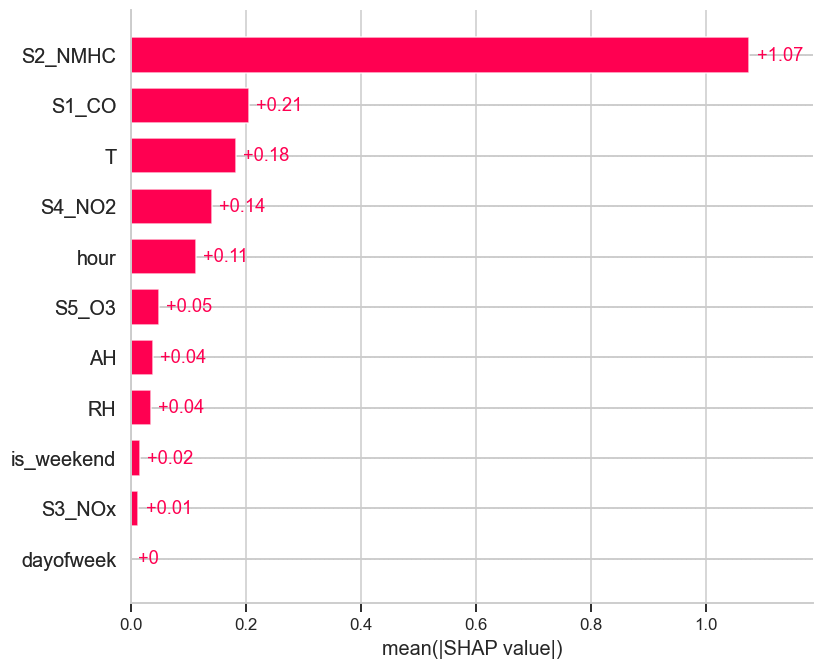

In [43]:
shap.plots.bar(shap_values, max_display=11)

### 6.2 Beeswarm plot — direction and spread of each feature's effect

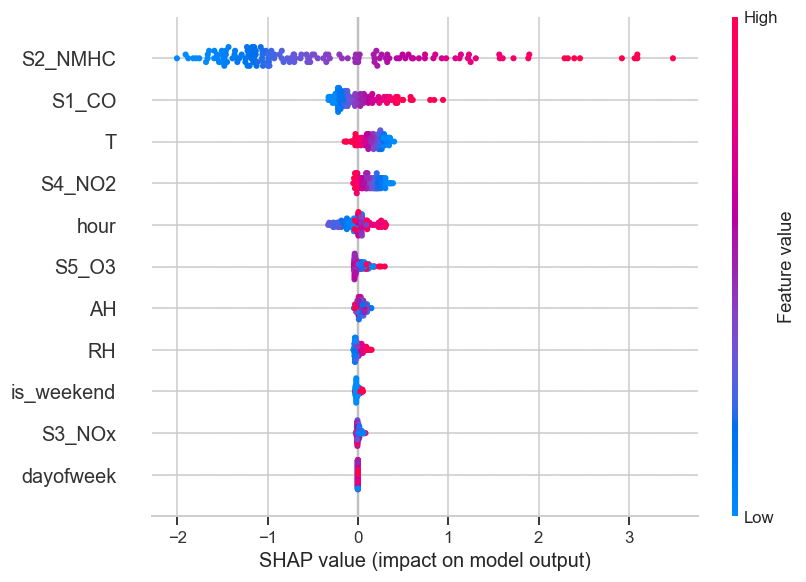

In [44]:
shap.plots.beeswarm(shap_values, max_display=11)

### 6.3 Waterfall plots — local explanations

High-pollution hour: 2005-03-24 20:00:00 | predicted CO = 7.17


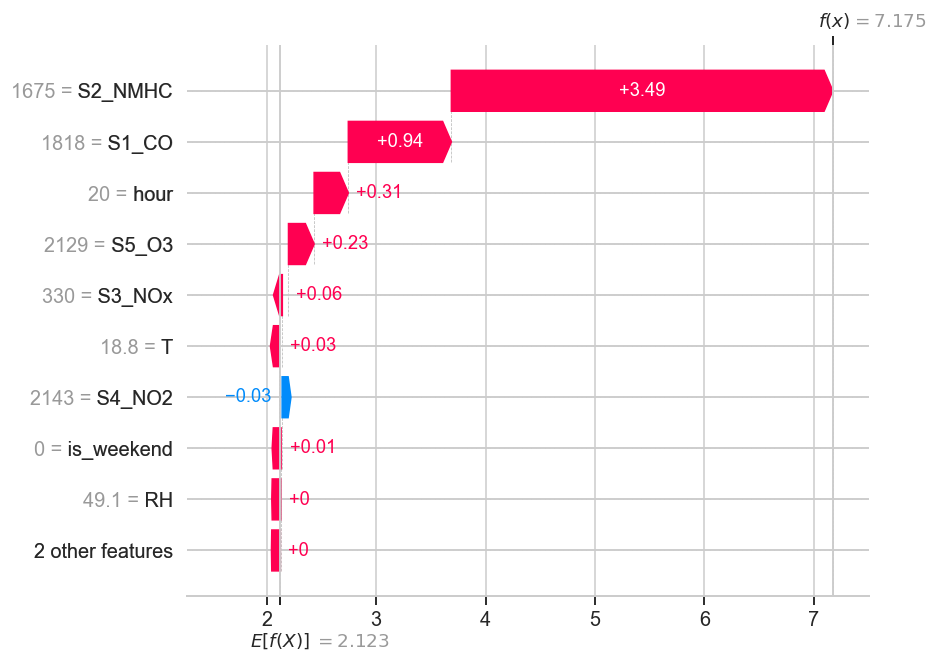

In [45]:
i_high = X_shap.index.get_loc(peak_hour)
print("High-pollution hour:", peak_hour, "| predicted CO =", round(test_pred[peak_hour], 2))
shap.plots.waterfall(shap_values[i_high], max_display=10)

Clean-air hour: 2005-03-29 03:00:00 | predicted CO = 0.33


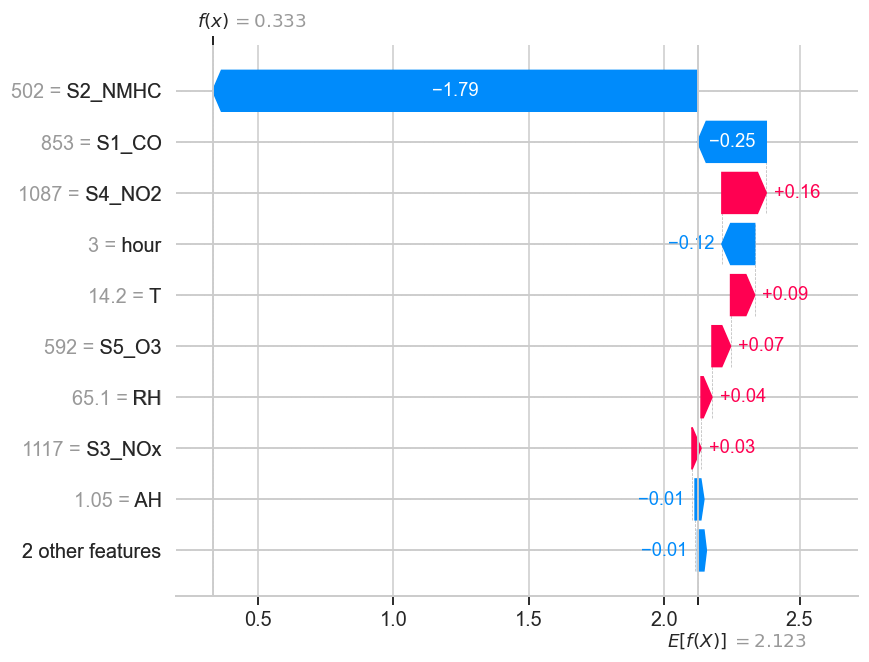

In [46]:
i_low = X_shap.index.get_loc(clean_hour)
print("Clean-air hour:", clean_hour, "| predicted CO =", round(test_pred[clean_hour], 2))
shap.plots.waterfall(shap_values[i_low], max_display=10)

### 6.4 Dependence plots — how the main features act

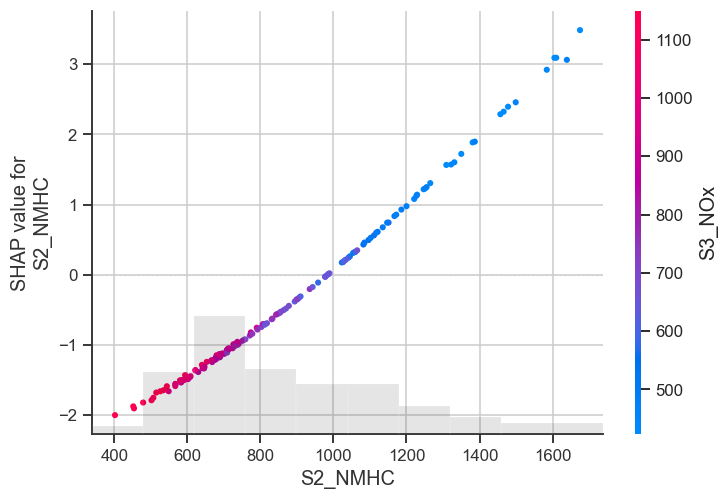

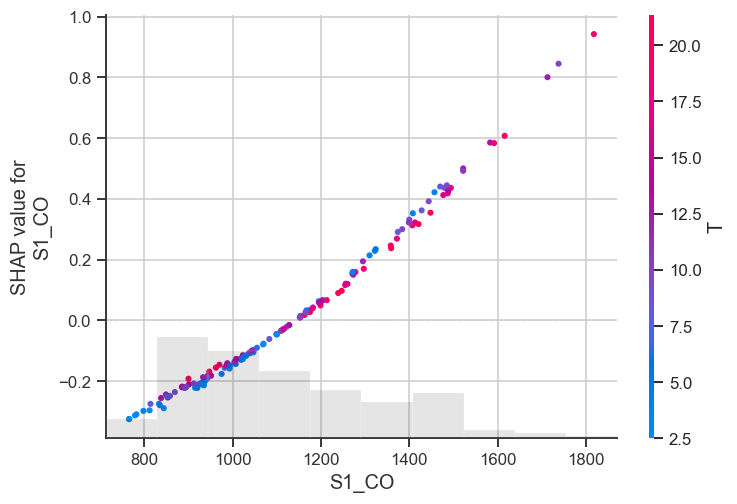

In [47]:
top = X_shap.columns[np.argsort(-np.abs(shap_values.values).mean(0))][:2]
for f in top:
    shap.plots.scatter(shap_values[:, f], color=shap_values)

### 6.5 Cross-check: do SVR and XGBoost rely on the same features?
SVR and XGBoost are almost tied in CV but work very differently. If both rank the features the same way, the explanation reflects the data rather than one model. XGBoost is explained exactly with TreeExplainer, on the same test hours.

In [48]:
xgb_shap = shap.TreeExplainer(fitted["XGBoost (tuned)"])(X_shap)
importance = pd.DataFrame({best_name: np.abs(shap_values.values).mean(0),
                           "XGBoost (tuned)": np.abs(xgb_shap.values).mean(0)},
                          index=X_shap.columns).sort_values(best_name, ascending=False)
importance.round(3)

,"SVR (RBF kernel, tuned)",XGBoost (tuned)
S2_NMHC,1.075,0.978
S1_CO,0.206,0.164
T,0.183,0.144
S4_NO2,0.141,0.013
hour,0.113,0.108
S5_O3,0.049,0.067
AH,0.038,0.053
RH,0.035,0.020
is_weekend,0.016,0.000
S3_NOx,0.013,0.030


#### Summary: explainable AI
- **S2_NMHC dominates the predictions** (mean |SHAP| ≈ 1.08 mg/m³, vs ≈ 0.21 for S1_CO and ≈ 0.18 for temperature), confirming the EDA (S2 correlates with CO more than S1: 0.92 vs 0.88): the hydrocarbon sensor tracks traffic exhaust better than the CO sensor.
- **XGBoost agrees** (Section 6.5): same ranking, with S2 far ahead. The one difference is S4_NO2, used by SVR (0.14) but hardly by XGBoost (0.02).
- **S1 and S2 are strongly correlated** (r = 0.89), so how the credit is split between them is checked directly in Section 7.5.
- **Directions:** high S2 and S1 values and evening hours push the prediction up; night hours, high temperature and high S4 push it down.
- **Calendar:** `is_weekend` and `dayofweek` add almost nothing once the sensors and the hour are known.
- **Waterfalls:** the peak hour (24 Mar 2005, 20:00, ≈ 7.2 mg/m³) is driven by S2 (+3.5) and S1 (+0.9); the cleanest hour (29 Mar 2005, 03:00, ≈ 0.3) by low S2 (−1.8).

## 7. Innovative insights

### 7.1 Random split vs chronological split: the cost of ignoring time
Sections 7.1 and 7.3 use the tuned **XGBoost**: it is almost tied with the selected SVR in CV (0.465 vs 0.460) and trains in about a second, and the questions tested here (how to split the data, which features leak) do not depend on the model family.

In [49]:
rand_test = data.sample(frac=0.2, random_state=RANDOM_STATE)
rand_train = data.drop(rand_test.index)
m = XGBRegressor(**xgb_grid.best_params_, random_state=RANDOM_STATE).fit(rand_train[FEATURES], rand_train[TARGET])
r_rand = evaluate("XGBoost - random split", rand_test[TARGET], m.predict(rand_test[FEATURES]))
r_time = res.loc["XGBoost (tuned)", METRIC_COLS].to_dict() | {"Model": "XGBoost - chronological split"}
pd.DataFrame([r_rand, r_time]).set_index("Model").round(3)

,MAE,MSE,RMSE,R2
Model,,,,
XGBoost - random split,0.245,0.144,0.379,0.926
XGBoost - chronological split,0.301,0.213,0.461,0.873


A random split gives a much more optimistic score because the model sees neighbouring hours (and future sensor behaviour) during training. The chronological split is the honest estimate for a real deployment.

### 7.2 Sensor drift: does the error grow over the test period?
The absolute error grows with the CO level, so each week's MAE is divided by that week's mean CO (relative error). Weeks with fewer than 84 measured hours (the partial weeks at the edges of the test period) are dropped.

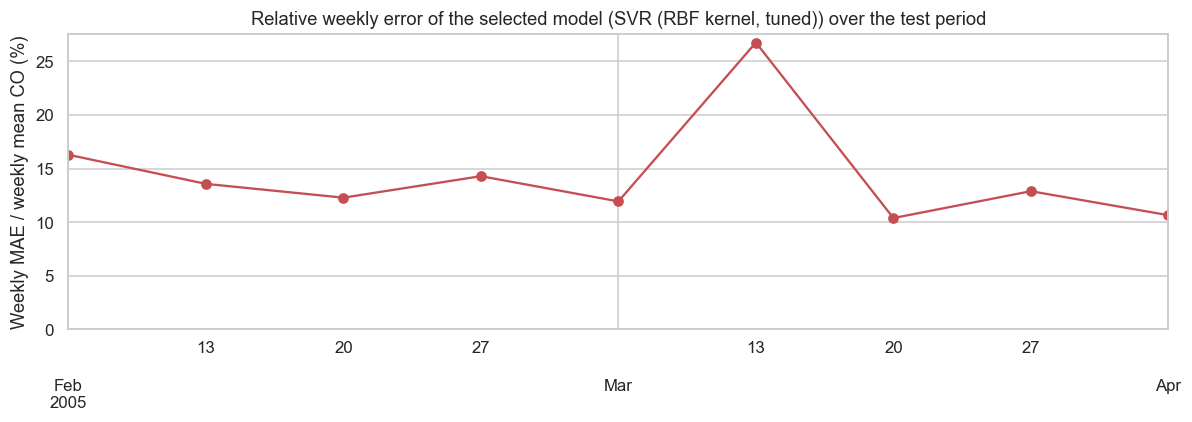

,MAE,mean_CO,hours,relative_MAE_pct
Datetime,,,,
2005-02-06,0.365,2.239,142,16.292
2005-02-13,0.305,2.248,91,13.574
2005-02-20,0.210,1.709,166,12.286
2005-02-27,0.296,2.072,165,14.292
2005-03-06,0.207,1.733,166,11.937
2005-03-13,0.483,1.806,155,26.767
2005-03-20,0.240,2.307,165,10.383
2005-03-27,0.298,2.313,166,12.890
2005-04-03,0.156,1.461,166,10.649


In [50]:
# Weekly error of the selected model over the test period, relative to the CO level of each week
MIN_HOURS_PER_WEEK = 84   # at least half of the week measured; partial weeks at the edges are dropped
err = pd.DataFrame({"abs_err": np.abs(y_test - preds[best_name]), "CO": y_test}, index=test.index)
weekly = err.resample("W").agg({"abs_err": "mean", "CO": ["mean", "size"]})
weekly.columns = ["MAE", "mean_CO", "hours"]
weekly = weekly[weekly["hours"] >= MIN_HOURS_PER_WEEK]
weekly["relative_MAE_pct"] = weekly["MAE"] / weekly["mean_CO"] * 100

ax = weekly["relative_MAE_pct"].plot(marker="o", figsize=(11, 4), color="#C44E52")
ax.set_ylim(0, None); ax.set_xlabel("")
ax.set_ylabel("Weekly MAE / weekly mean CO (%)")
ax.set_title(f"Relative weekly error of the selected model ({best_name}) over the test period")
plt.tight_layout(); plt.show()
weekly.round(3)

#### Interpretation: error over the test period
- The relative error stays between 10% and 17% of the CO level in 8 of the 9 full weeks, with no upward trend: within these 9 weeks there is no visible drift.
- One week stands out (week ending 13 March 2005: 27%). It is isolated: the error returns to 10–13% in the following weeks.
- Nine weeks are too short to judge drift; Section 7.4 looks at the whole second half of the year.

### 7.3 Why `month` is excluded: a leakage test
The data covers only ~13 months. With a chronological split, the test period (February – April 2005) contains calendar months that the model saw in **2004** (March, April), under different conditions (sensor age, weather), and February never appears in training. Here we add `month` as a feature and compare both splits.

In [51]:
print("Months in train:", sorted(train.index.month.unique()))
print("Months in test :", sorted(test.index.month.unique()))

FEATURES_M = FEATURES + ["month"]
params = dict(**xgb_grid.best_params_, random_state=RANDOM_STATE)
rows = []
for feats, label in [(FEATURES, "without month"), (FEATURES_M, "with month")]:
    m_t = XGBRegressor(**params).fit(train[feats], y_train)
    rows.append(evaluate(f"Chronological split - {label}", y_test, m_t.predict(test[feats])))
    m_r = XGBRegressor(**params).fit(rand_train[feats], rand_train[TARGET])
    rows.append(evaluate(f"Random split - {label}", rand_test[TARGET], m_r.predict(rand_test[feats])))
leak = pd.DataFrame(rows).set_index("Model").round(3)
leak

Months in train: [1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Months in test : [2, 3, 4]


,MAE,MSE,RMSE,R2
Model,,,,
Chronological split - without month,0.301,0.213,0.461,0.873
Random split - without month,0.245,0.144,0.379,0.926
Chronological split - with month,0.312,0.228,0.477,0.864
Random split - with month,0.244,0.133,0.365,0.932


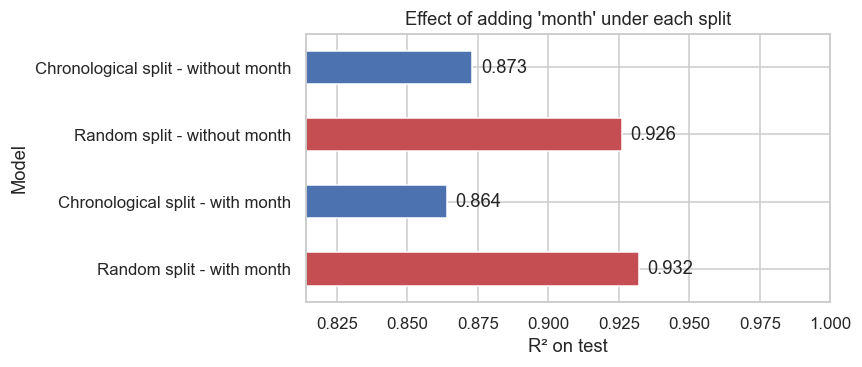

In [52]:
ax = leak["R2"].plot.barh(figsize=(8, 3.5), color=["#4C72B0", "#C44E52"] * 2)
ax.invert_yaxis(); ax.set_xlim(leak["R2"].min() - 0.05, 1)
ax.set_xlabel("R² on test"); ax.set_title("Effect of adding 'month' under each split")
for i, v in enumerate(leak["R2"]): ax.text(v + 0.003, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

#### Interpretation of the leakage test
- **Random split:** adding `month` improves R² (0.927 → 0.932).
- **Chronological split:** adding `month` lowers R² (0.874 → 0.865; RMSE 0.459 → 0.476).
- **Why:** in a random split, hours of the same month fall in both train and test, so the model memorises each month's level; on the future period that no longer works (February is never seen, and March/April 2005 differ from 2004).
- **Consequence:** we use a chronological split and exclude `month` and `season` from the model.

### 7.4 Recalibration: how long does a calibration stay valid?
The test period (9 weeks) is too short to see drift, so we simulate a deployment from September 2004 to March 2005 with the selected model and three strategies: **frozen** (calibrated once with March–August 2004), **recalibrated monthly with all past data**, and **recalibrated monthly with the last 60 days**. Each month is predicted only with earlier data. Nothing is tuned or selected here, so using the test months is not leakage.

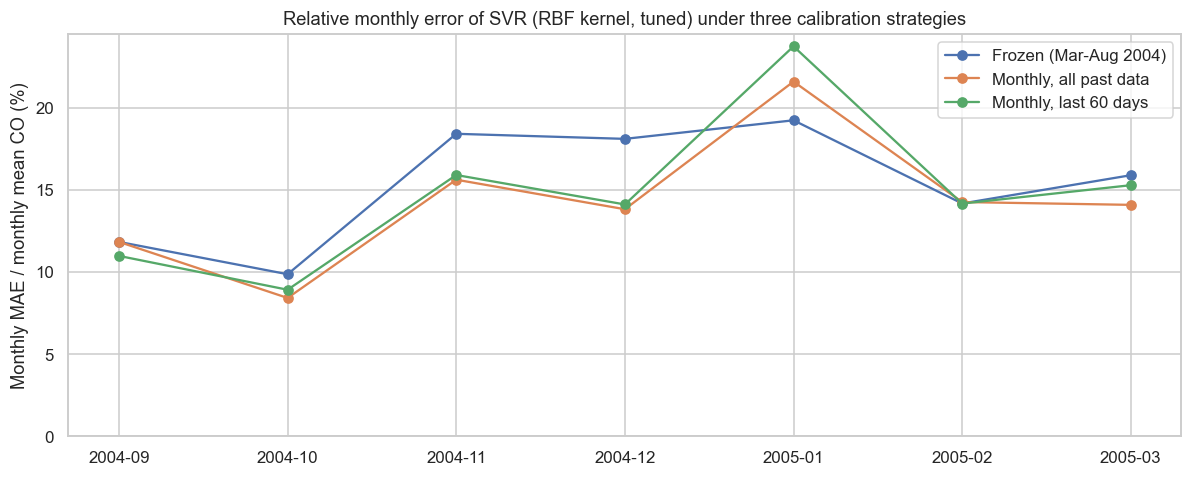

strategy,Frozen (Mar-Aug 2004),"Monthly, all past data","Monthly, last 60 days"
month,,,
2004-09,11.8,11.8,11.0
2004-10,9.9,8.4,8.9
2004-11,18.4,15.6,15.9
2004-12,18.1,13.8,14.1
2005-01,19.2,21.6,23.7
2005-02,14.2,14.3,14.2
2005-03,15.9,14.1,15.3
Average,15.4,14.2,14.7


In [53]:
FIRST_EVAL_MONTH = pd.Period("2004-09", "M")   # the frozen model is calibrated on everything before this month
RECENT_WINDOW_DAYS = 60
MIN_HOURS_PER_MONTH = 300                       # skip months with too little data (April 2005 has only 4 days)

calibration = data[data.index < FIRST_EVAL_MONTH.start_time]
frozen = clone(fitted[best_name]).fit(calibration[FEATURES], calibration[TARGET])

rows = []
for month in data.index.to_period("M").unique():
    month_data = data[data.index.to_period("M") == month]
    if month < FIRST_EVAL_MONTH or len(month_data) < MIN_HOURS_PER_MONTH:
        continue
    past = data[data.index < month.start_time]
    recent = past[past.index >= month.start_time - pd.Timedelta(days=RECENT_WINDOW_DAYS)]
    strategies = {
        "Frozen (Mar-Aug 2004)": frozen,
        "Monthly, all past data": clone(fitted[best_name]).fit(past[FEATURES], past[TARGET]),
        f"Monthly, last {RECENT_WINDOW_DAYS} days": clone(fitted[best_name]).fit(recent[FEATURES], recent[TARGET]),
    }
    for strategy, model in strategies.items():
        mae = mean_absolute_error(month_data[TARGET], model.predict(month_data[FEATURES]))
        rows.append({"month": str(month), "strategy": strategy, "relative_MAE_pct": mae / month_data[TARGET].mean() * 100})

recal = pd.DataFrame(rows).pivot(index="month", columns="strategy", values="relative_MAE_pct")
ax = recal.plot(marker="o", figsize=(11, 4.5))
ax.set_ylim(0, None); ax.set_xlabel("")
ax.set_ylabel("Monthly MAE / monthly mean CO (%)")
ax.set_title(f"Relative monthly error of {best_name} under three calibration strategies")
ax.legend(title="")
plt.tight_layout(); plt.show()

recal.loc["Average"] = recal.mean()
recal.round(1)

#### Interpretation: recalibration
- **The frozen calibration degrades:** from 10–12% of the CO level in September–October to 14–19% from November to March.
- **Monthly recalibration with all past data helps in most months** (by up to 4.3 points in December) but not in January (21.6% vs 19.2%); on average 14.2% vs 15.4%.
- **Using only the last 60 days is not better** (14.7% on average).
- **Conclusion:** regular recalibration with all available data is worth it, but it only partly offsets the rise in error, which is largely seasonal; with one year of data, sensor drift cannot be separated from the change of season.

### 7.5 Which inputs are really needed? A drop-one-feature test
SHAP cannot tell whether one of two correlated sensors (S1 and S2) is redundant, so we retrain the models without one input at a time and measure the change in error. An input is removed by replacing it with its training mean, which removes its information without changing the pipelines.

In [54]:
DROP_MODELS = [best_name, "XGBoost (tuned)"]
rows = []
for feature in [None] + NUMERIC_INPUTS:
    X_tr, X_te = X_train, X_test
    if feature is not None:
        constant = X_train[feature].mean()
        X_tr, X_te = X_train.assign(**{feature: constant}), X_test.assign(**{feature: constant})
    row = {"input removed": feature or "(none)"}
    for name in DROP_MODELS:
        model = clone(fitted[name])
        row[f"{name}: CV RMSE"] = -cross_val_score(model, X_tr, y_train, cv=tscv, scoring=CV_SCORING, n_jobs=-1).mean()
        row[f"{name}: test R2"] = r2_score(y_test, model.fit(X_tr, y_train).predict(X_te))
    rows.append(row)
pd.DataFrame(rows).set_index("input removed").round(3)

,"SVR (RBF kernel, tuned): CV RMSE","SVR (RBF kernel, tuned): test R2",XGBoost (tuned): CV RMSE,XGBoost (tuned): test R2
input removed,,,,
(none),0.460,0.889,0.467,0.873
S1_CO,0.483,0.892,0.481,0.875
S2_NMHC,0.579,0.817,0.569,0.776
S3_NOx,0.461,0.889,0.465,0.875
S4_NO2,0.441,0.887,0.465,0.872
S5_O3,0.465,0.888,0.465,0.878
T,0.458,0.888,0.465,0.873
RH,0.458,0.888,0.470,0.873
AH,0.451,0.888,0.463,0.873


#### Interpretation: drop-one-feature test
- **S2 is irreplaceable:** without it, CV RMSE rises from 0.460 to 0.579 for SVR (test R² 0.889 → 0.817), and similarly for XGBoost.
- **S1, the dedicated CO sensor, is nearly redundant once S2 is present:** CV RMSE 0.460 → 0.483, with no loss on the test period (R² 0.892).
- **Every other input is individually replaceable** (CV RMSE changes by at most 0.02), since they share the weather information.
- **Removing S4 improves the SVR's CV RMSE** (0.441) but not its test score (R² 0.887). This fits its drifting baseline (Section 4.6), but all inputs are kept: choosing inputs with this same CV would make it optimistic.

## 8. Conclusion
- **Data:** `-200` codes, NMHC dropped (90% missing), 366 h of device failure removed; reference gaps interpolated only for the EDA, never for modelling.
- **EDA:** traffic drives CO (weekday peaks at 8–9 h and 19 h, Sunday cleanest; the evening peak dominates outside summer), with an autumn maximum and an August minimum. S2 tracks CO best (r = 0.92), the NO2 sensor follows NO2 within a month (r ≈ 0.70) but its baseline drifts, so over the year r is only 0.17, and benzene ground truth appears to be computed from S2.
- **Modelling:** the selected SVR (RBF kernel) predicts CO on the future period with **RMSE 0.432 mg/m³, MAE 0.280, R² 0.889**, 50% less error than the single-sensor calibration; tuned XGBoost is effectively tied.
- **XAI:** S2 is the main driver, followed by S1, temperature and hour of day; SVR and XGBoost agree.
- **Innovative insights:** a random split overstates performance (R² 0.927 vs 0.874) and makes `month` look useful when it is leakage; S2 is irreplaceable while the dedicated CO sensor S1 is nearly redundant; the NO2 sensor shows how a drifting baseline hides a real response; a frozen calibration degrades over the following months (from about 11% to 14–19% relative error), and monthly recalibration only partly helps.